In [2]:
# 1. Cài đặt và cập nhật thư viện hỗ trợ YOLO11
!pip install -U ultralytics roboflow opencv-python seaborn matplotlib

import os
import yaml
from roboflow import Roboflow
from ultralytics import YOLO

print("=== BƯỚC 1: TẢI DỮ LIỆU TỪ ROBOFLOW ===")
rf = Roboflow(api_key="StNCnuoOoDPyDZIEEoWH") 
project = rf.workspace("dentex").project("dentex-3xe7e")
version = project.version(4)
dataset = version.download("yolov8") 

print("\n=== BƯỚC 2: CẤU HÌNH LẠI ĐƯỜNG DẪN YAML ===")
yaml_path = '/kaggle/working/dentex-4/data.yaml'

with open(yaml_path, 'r') as file:
    data = yaml.safe_load(file)

data['path'] = '/kaggle/working/dentex-4'
data['train'] = 'train/images'

if os.path.exists('/kaggle/working/dentex-4/val/images'):
    data['val'] = 'val/images'
elif os.path.exists('/kaggle/working/dentex-4/valid/images'):
    data['val'] = 'valid/images'
else:
    data['val'] = 'train/images'

with open(yaml_path, 'w') as file:
    yaml.dump(data, file, default_flow_style=False)
print("Đã sửa xong file data.yaml! Dữ liệu đã sẵn sàng.")

print("\n=== BƯỚC 3: BẮT ĐẦU HUẤN LUYỆN VỚI YOLO11 ===")
model = YOLO('yolo11n.pt') 

# Bắt đầu train 50 vòng
results = model.train(data='/kaggle/working/dentex-4/data.yaml', epochs=50, imgsz=640, device=0)
print("TRAIN XONG! Mô hình đã được lưu tại: /kaggle/working/runs/detect/train/weights/best.pt")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 4.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 37.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 104.8 MB/s eta 0:00:0000:01
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-big


Extracting Dataset Version Zip to dentex-4 in yolov8:: 100%|██████████| 1419/1419 [00:00<00:00, 2418.85it/s]



=== BƯỚC 2: CẤU HÌNH LẠI ĐƯỜNG DẪN YAML ===
Đã sửa xong file data.yaml! Dữ liệu đã sẵn sàng.

=== BƯỚC 3: BẮT ĐẦU HUẤN LUYỆN VỚI YOLO11 ===
Ultralytics 8.4.53 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dentex-4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=


0: 384x640 9 Cariess, 2 Impacteds, 52.9ms
Speed: 2.0ms preprocess, 52.9ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


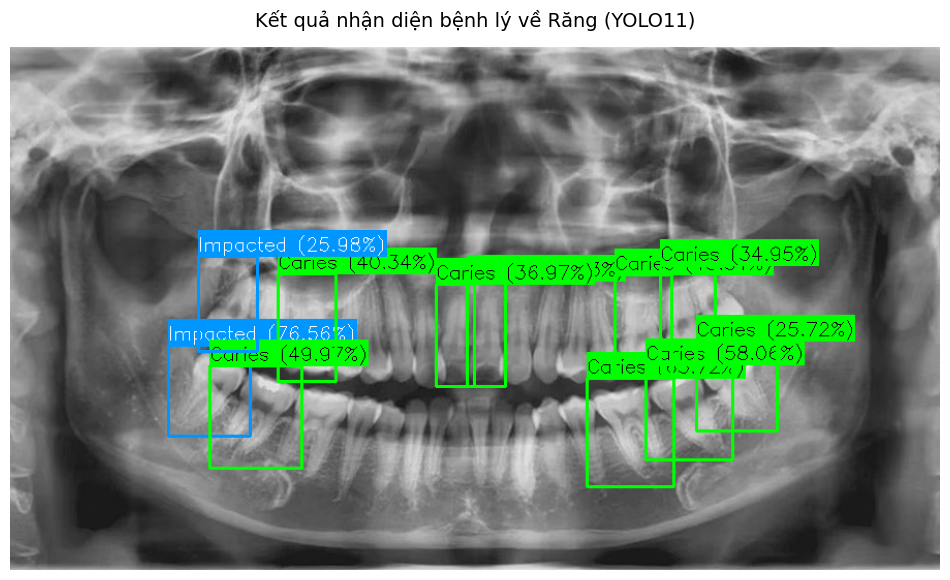

In [3]:
!pip install -q -U ultralytics opencv-python matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import os

# 1. Cấu hình đường dẫn dữ liệu và mô hình
image_path = '/kaggle/input/datasets/ngtrungchinh/testanh/dental-x-ray.avif'
model_path = '/kaggle/input/models/ngtrungchinh/yolo11-dentex-model/pytorch/default/1/best (1).pt'

# Kiểm tra tính hợp lệ của file đầu vào
if not os.path.exists(image_path):
    raise FileNotFoundError(f"Không tìm thấy file ảnh tại: {image_path}")
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Không tìm thấy trọng số mô hình tại: {model_path}")

# 2. Khởi tạo mô hình YOLO11
model = YOLO(model_path)

# 3. Tiền xử lý ảnh đầu vào
# Sử dụng PIL để đọc định dạng .avif và chuyển đổi sang không gian màu RGB
img_pil = Image.open(image_path).convert('RGB')
img_rgb = np.array(img_pil)

# 4. Thực hiện suy luận (Inference) trên TẤT CẢ các nhãn bệnh lý
results = model.predict(source=img_rgb)
boxes = results[0].boxes 

# 5. Cấu hình màu sắc hiển thị (RGB) cho 4 loại bệnh lý
class_colors = {
    0: (0, 255, 0),    # Lớp 0 (Caries): Xanh lá
    1: (255, 0, 0),    # Lớp 1 (Deep Caries): Đỏ
    2: (0, 150, 255),  # Lớp 2 (Impacted): Xanh dương
    3: (255, 0, 255)   # Lớp 3 (Periapical Lesion): Tím
}

# 6. Trực quan hóa kết quả bằng OpenCV
for box in boxes:
    # Trích xuất tọa độ bounding box
    x1, y1, x2, y2 = map(int, box.xyxy[0]) 
    
    # Trích xuất độ tin cậy (Confidence score) và nhãn (Class ID)
    conf = float(box.conf[0])
    cls_id = int(box.cls[0])
    class_name = model.names[cls_id]
    
    # Xác định màu sắc tương ứng với lớp bệnh lý (mặc định màu vàng nếu ngoài danh sách)
    color = class_colors.get(cls_id, (255, 255, 0))
    
    # Cấu hình chuỗi văn bản
    label = f"{class_name} ({conf*100:.2f}%)"
    
    # Vẽ Bounding Box
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 2)
    
    # Vẽ background cho text để tăng độ tương phản
    (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
    cv2.rectangle(img_rgb, (x1, int(y1 - 25)), (int(x1 + w), y1), color, -1) 
    
    # Chèn text nhãn dự đoán (Đảo màu chữ để tăng khả năng đọc trên nền sáng/tối)
    text_color = (0, 0, 0) if cls_id == 0 else (255, 255, 255)
    cv2.putText(img_rgb, label, (x1, int(y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, text_color, 1)

# 7. Hiển thị ảnh kết quả
plt.figure(figsize=(12, 12))
plt.imshow(img_rgb)
plt.axis('off')
plt.title('Kết quả nhận diện bệnh lý về Răng (YOLO11)', fontsize=14, pad=15)
plt.show()

--- BƯỚC 1: TRÍCH XUẤT TẬP DỮ LIỆU ĐÁNH GIÁ (VALIDATION DATASET) ---
loading Roboflow workspace...
loading Roboflow project...

--- BƯỚC 2: CHUẨN HÓA CẤU HÌNH ĐƯỜNG DẪN DỮ LIỆU ---
Cấu hình data.yaml đã được cập nhật. Đường dẫn validation: train/images

--- BƯỚC 3: KHỞI TẠO MÔ HÌNH VÀ THỰC THI ĐÁNH GIÁ (VALIDATION) ---
Hệ thống đang tiến hành tính toán các ma trận đánh giá. Vui lòng chờ...
Ultralytics 8.4.53 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,932 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4709.7±513.4 MB/s, size: 346.6 KB)
val: Scanning /kaggle/working/dentex-4/train/labels.cache... 665 images, 24 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 665/665 121.3Mit/s 0.0s
train: /kaggle/working/dentex-4/train/images/train_377_png.rf.97dde9d39a9ba66db91b1ab54097ec3a.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95

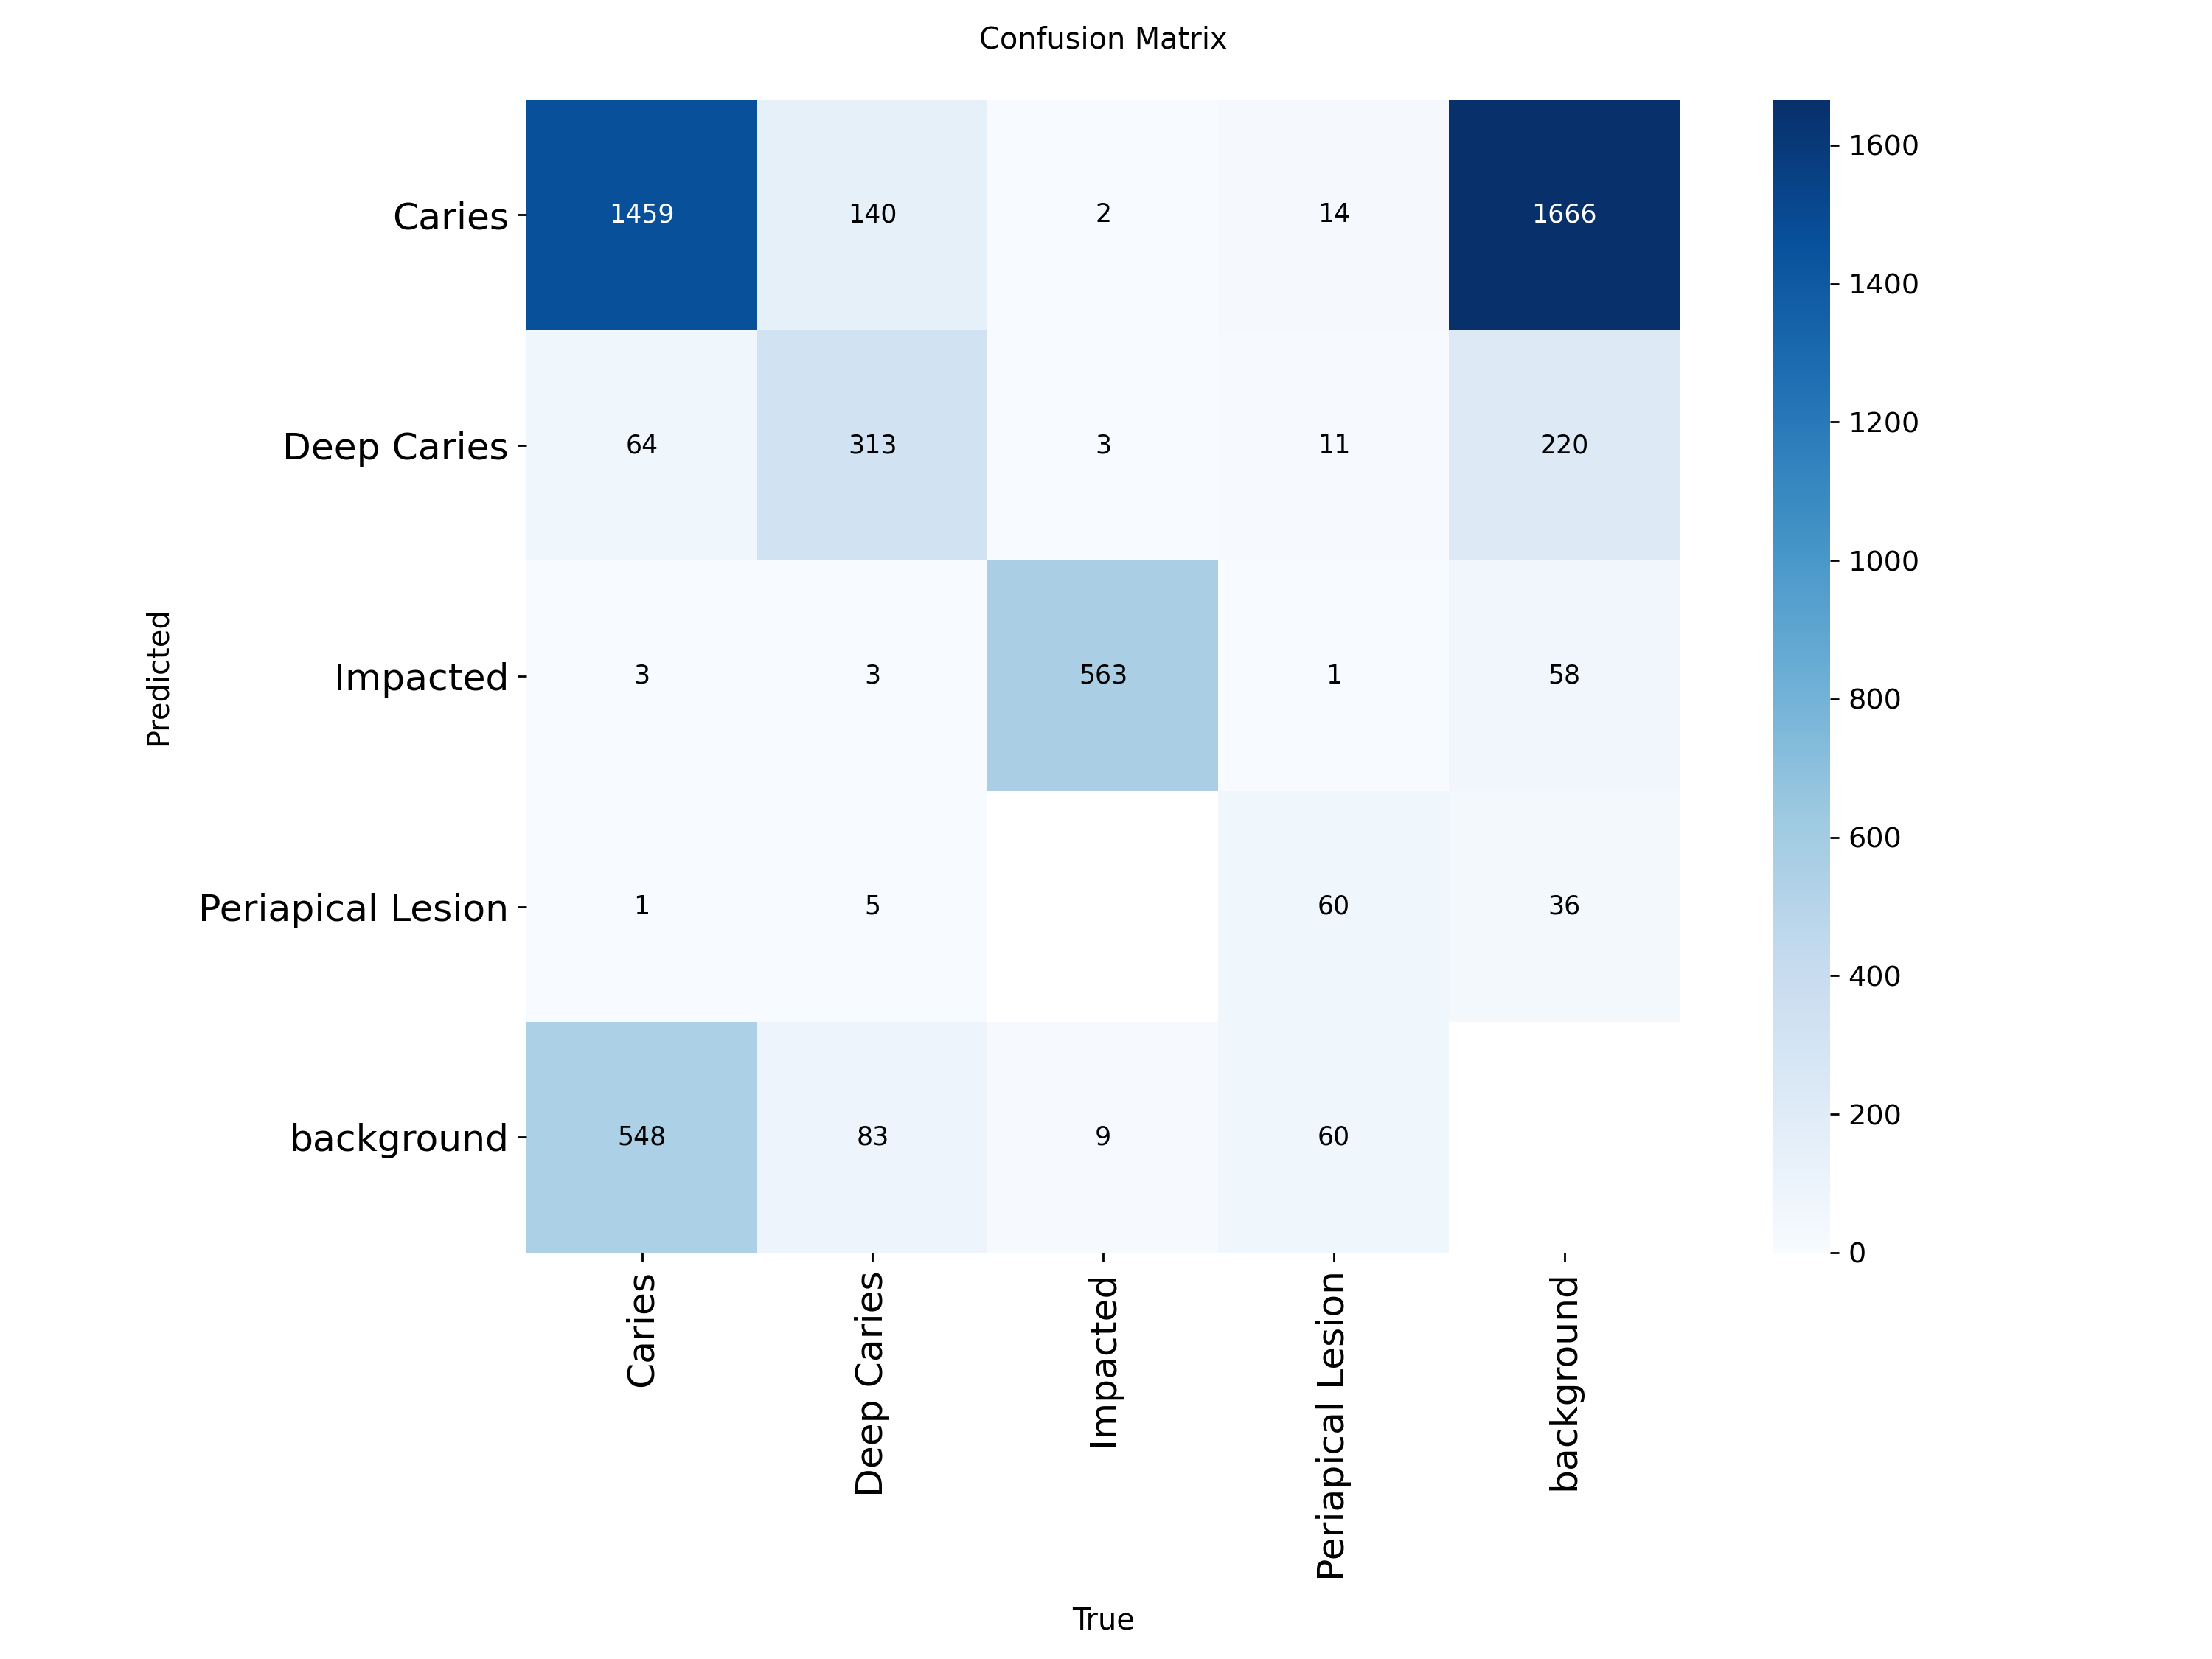

--------------------------------------------------------------------------------
Kết xuất biểu đồ: confusion_matrix_normalized.png


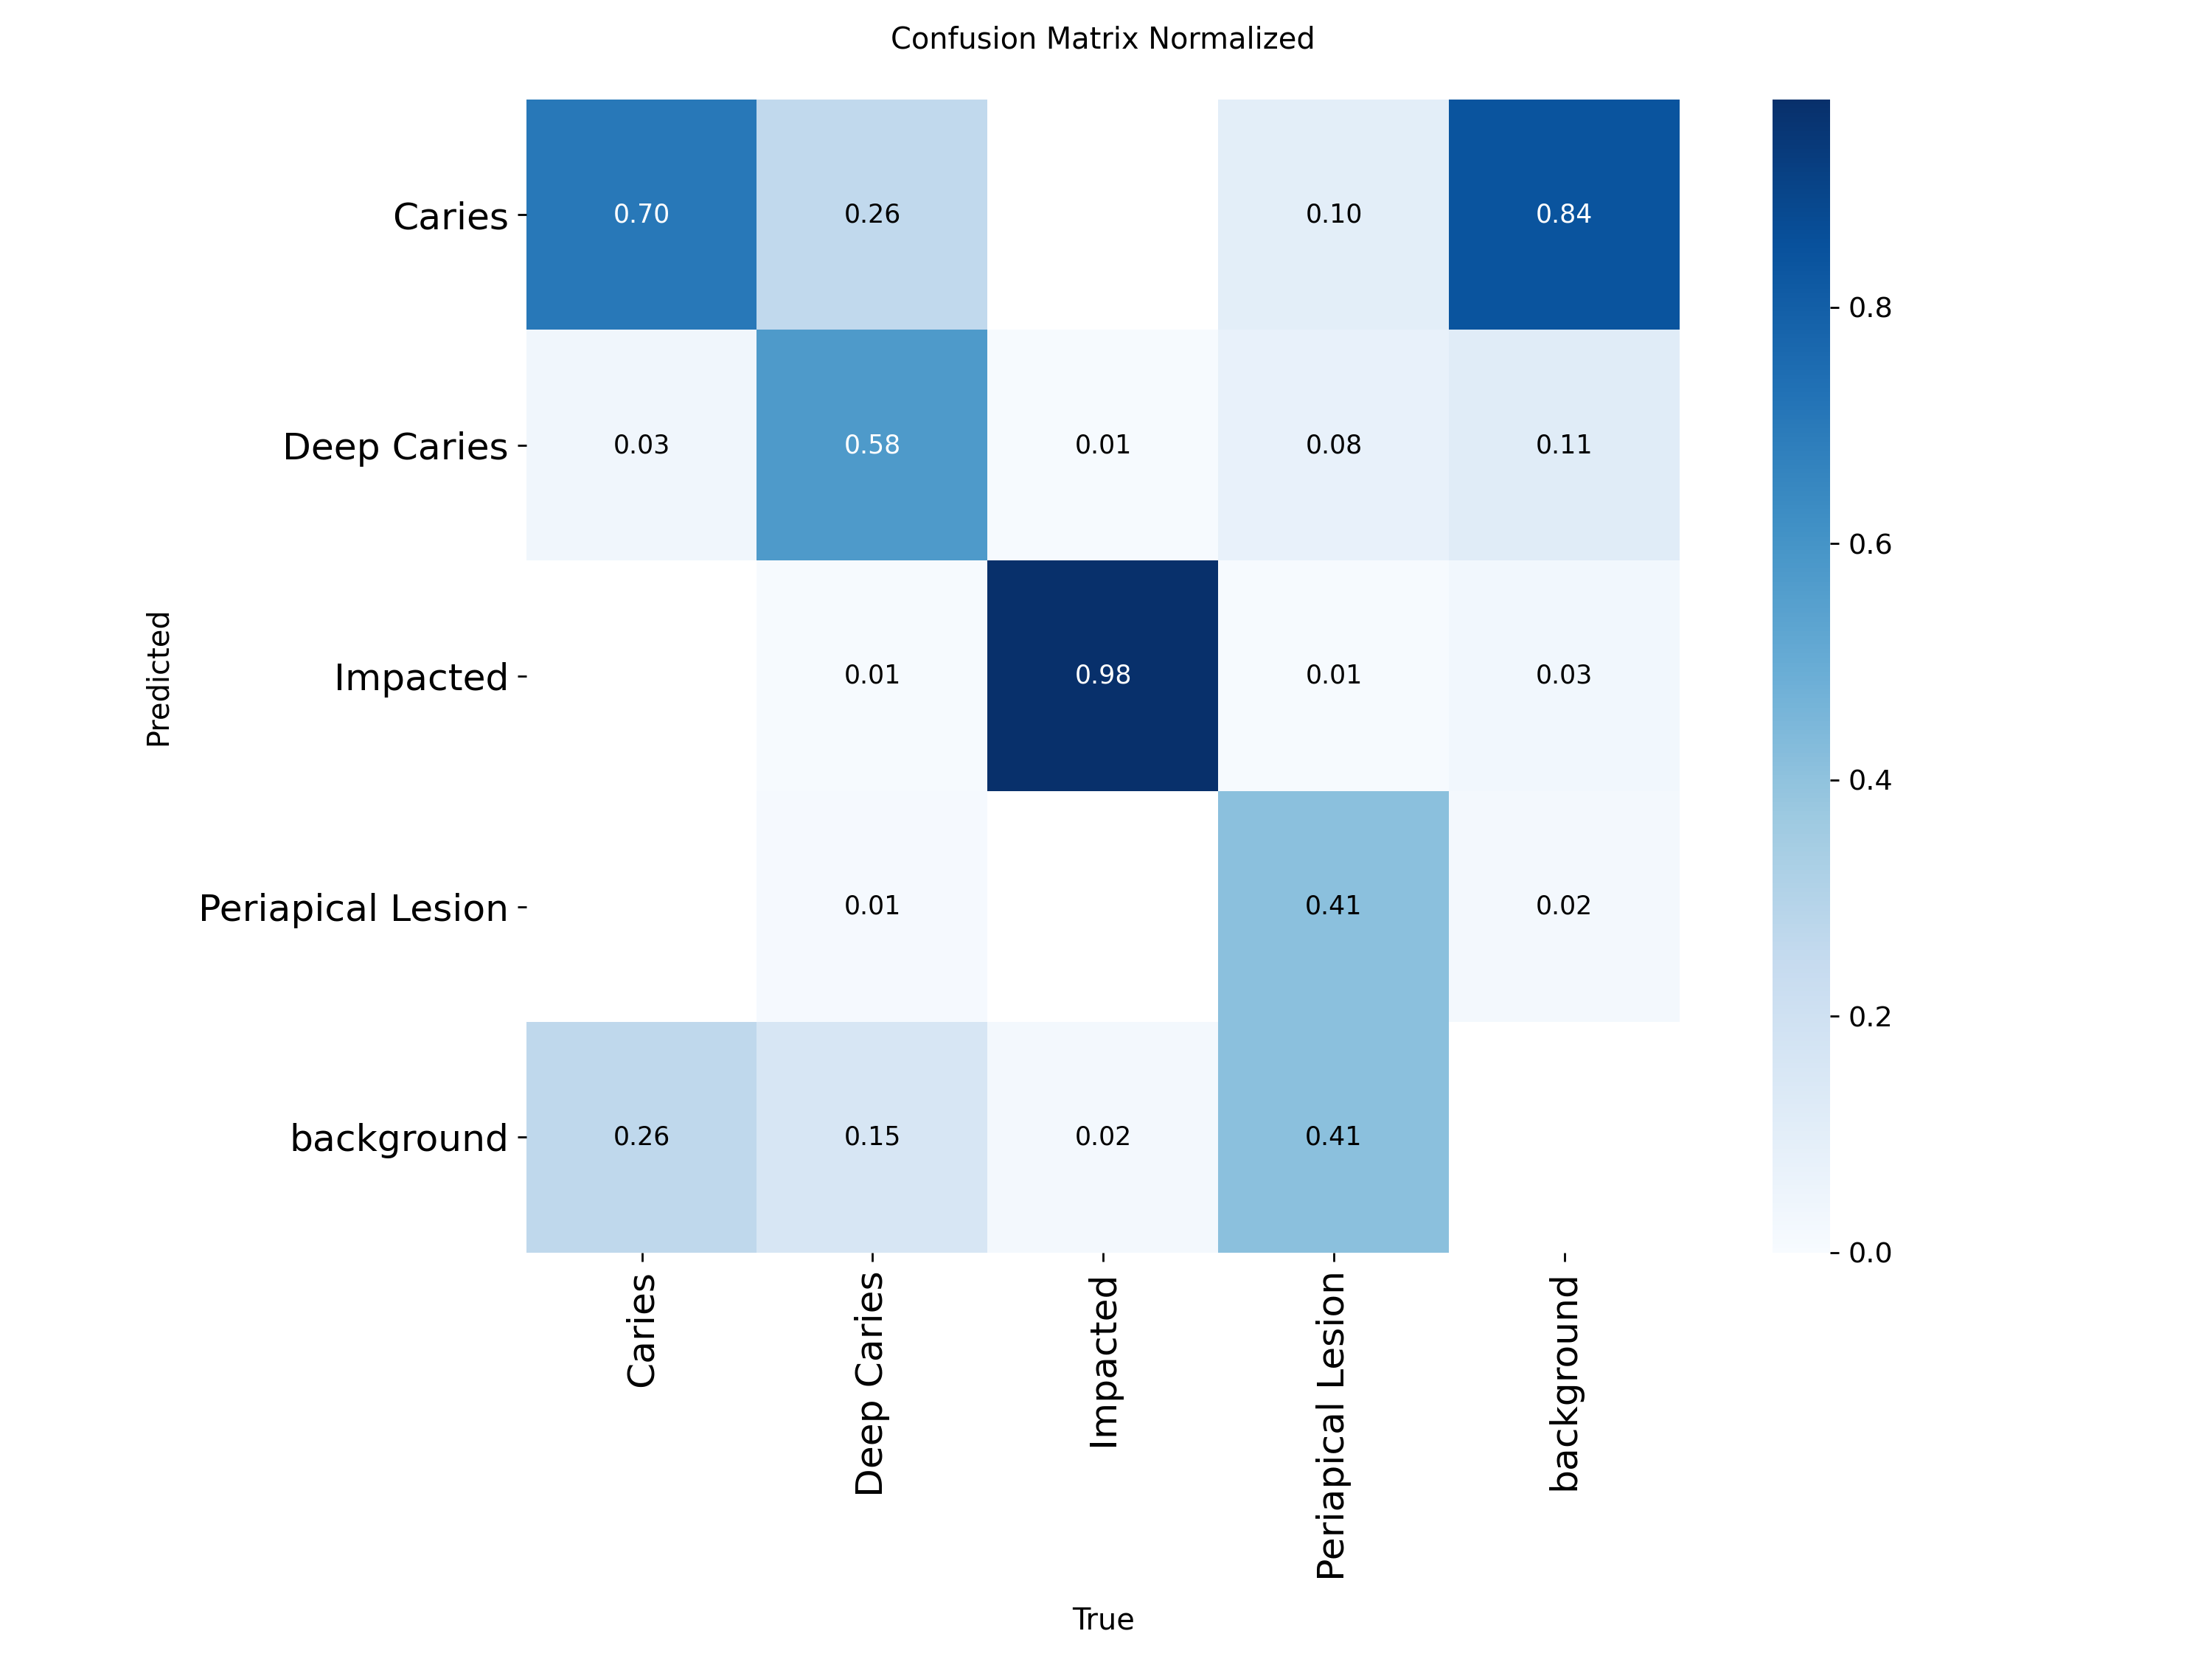

--------------------------------------------------------------------------------


In [4]:
!pip install -q -U ultralytics roboflow opencv-python matplotlib seaborn

import os
import glob
import yaml
from IPython.display import Image, display
from roboflow import Roboflow
from ultralytics import YOLO

print("--- BƯỚC 1: TRÍCH XUẤT TẬP DỮ LIỆU ĐÁNH GIÁ (VALIDATION DATASET) ---")
# Khởi tạo kết nối API và tải bộ dữ liệu từ Roboflow
rf = Roboflow(api_key="StNCnuoOoDPyDZIEEoWH")
project = rf.workspace("dentex").project("dentex-3xe7e")
dataset = project.version(4).download("yolov8")

print("\n--- BƯỚC 2: CHUẨN HÓA CẤU HÌNH ĐƯỜNG DẪN DỮ LIỆU ---")
yaml_path = f'{dataset.location}/data.yaml'

# Đọc cấu hình hiện tại
with open(yaml_path, 'r') as file:
    data = yaml.safe_load(file)

# Cập nhật đường dẫn tuyệt đối cho môi trường Kaggle
data['path'] = dataset.location
data['train'] = 'train/images'

# Xác thực và ánh xạ chính xác thư mục validation
val_path = os.path.join(dataset.location, 'val', 'images')
valid_path = os.path.join(dataset.location, 'valid', 'images')

if os.path.exists(val_path):
    data['val'] = 'val/images'
elif os.path.exists(valid_path):
    data['val'] = 'valid/images'
else:
    # Phương án dự phòng nếu cấu trúc thư mục bị thiếu
    data['val'] = 'train/images' 

# Lưu lại cấu hình chuẩn
with open(yaml_path, 'w') as file:
    yaml.dump(data, file, default_flow_style=False)
print(f"Cấu hình data.yaml đã được cập nhật. Đường dẫn validation: {data['val']}")

print("\n--- BƯỚC 3: KHỞI TẠO MÔ HÌNH VÀ THỰC THI ĐÁNH GIÁ (VALIDATION) ---")
model_weights_path = '/kaggle/input/models/ngtrungchinh/yolo11-dentex-model/pytorch/default/1/best (1).pt' 

# Kiểm tra tính hợp lệ của tệp trọng số
if not os.path.exists(model_weights_path):
    raise FileNotFoundError(f"Không tìm thấy trọng số mô hình tại: {model_weights_path}")

# Khởi tạo mô hình YOLO11 với trọng số tốt nhất
model = YOLO(model_weights_path)

print("Hệ thống đang tiến hành tính toán các ma trận đánh giá. Vui lòng chờ...")
# Thực thi đánh giá mô hình trên tập validation
metrics = model.val(data=yaml_path)

print("\n--- BƯỚC 4: TRỰC QUAN HÓA CÁC CHỈ SỐ ĐÁNH GIÁ ---")
# Truy xuất thư mục lưu trữ kết quả validation mới nhất do YOLO sinh ra
val_directories = glob.glob('/kaggle/working/runs/detect/val*')

if val_directories:
    latest_val_dir = max(val_directories, key=os.path.getmtime)

    # Danh sách các biểu đồ cần trích xuất cho báo cáo
    evaluation_plots = [
        'confusion_matrix.png',           
        'confusion_matrix_normalized.png',
        'PR_curve.png',                   
        'F1_curve.png'                    
    ]

    plots_found = False
    for plot_name in evaluation_plots:
        plot_path = os.path.join(latest_val_dir, plot_name)
        if os.path.exists(plot_path):
            print(f"Kết xuất biểu đồ: {plot_name}")
            display(Image(filename=plot_path, width=800))
            print("-" * 80)
            plots_found = True
            
    if not plots_found:
        print(f"Cảnh báo: Không tìm thấy tệp hình ảnh biểu đồ trong thư mục {latest_val_dir}.")
else:
    print("Cảnh báo: Quá trình đánh giá không tạo ra thư mục kết quả.")

=== QUÉT TOÀN BỘ BIỂU ĐỒ TRONG THƯ MỤC KẾT QUẢ ===
-> Đang lục lọi trong thư mục: /kaggle/working/runs/detect/val

 ĐÃ TÌM THẤY: confusion_matrix_normalized.png


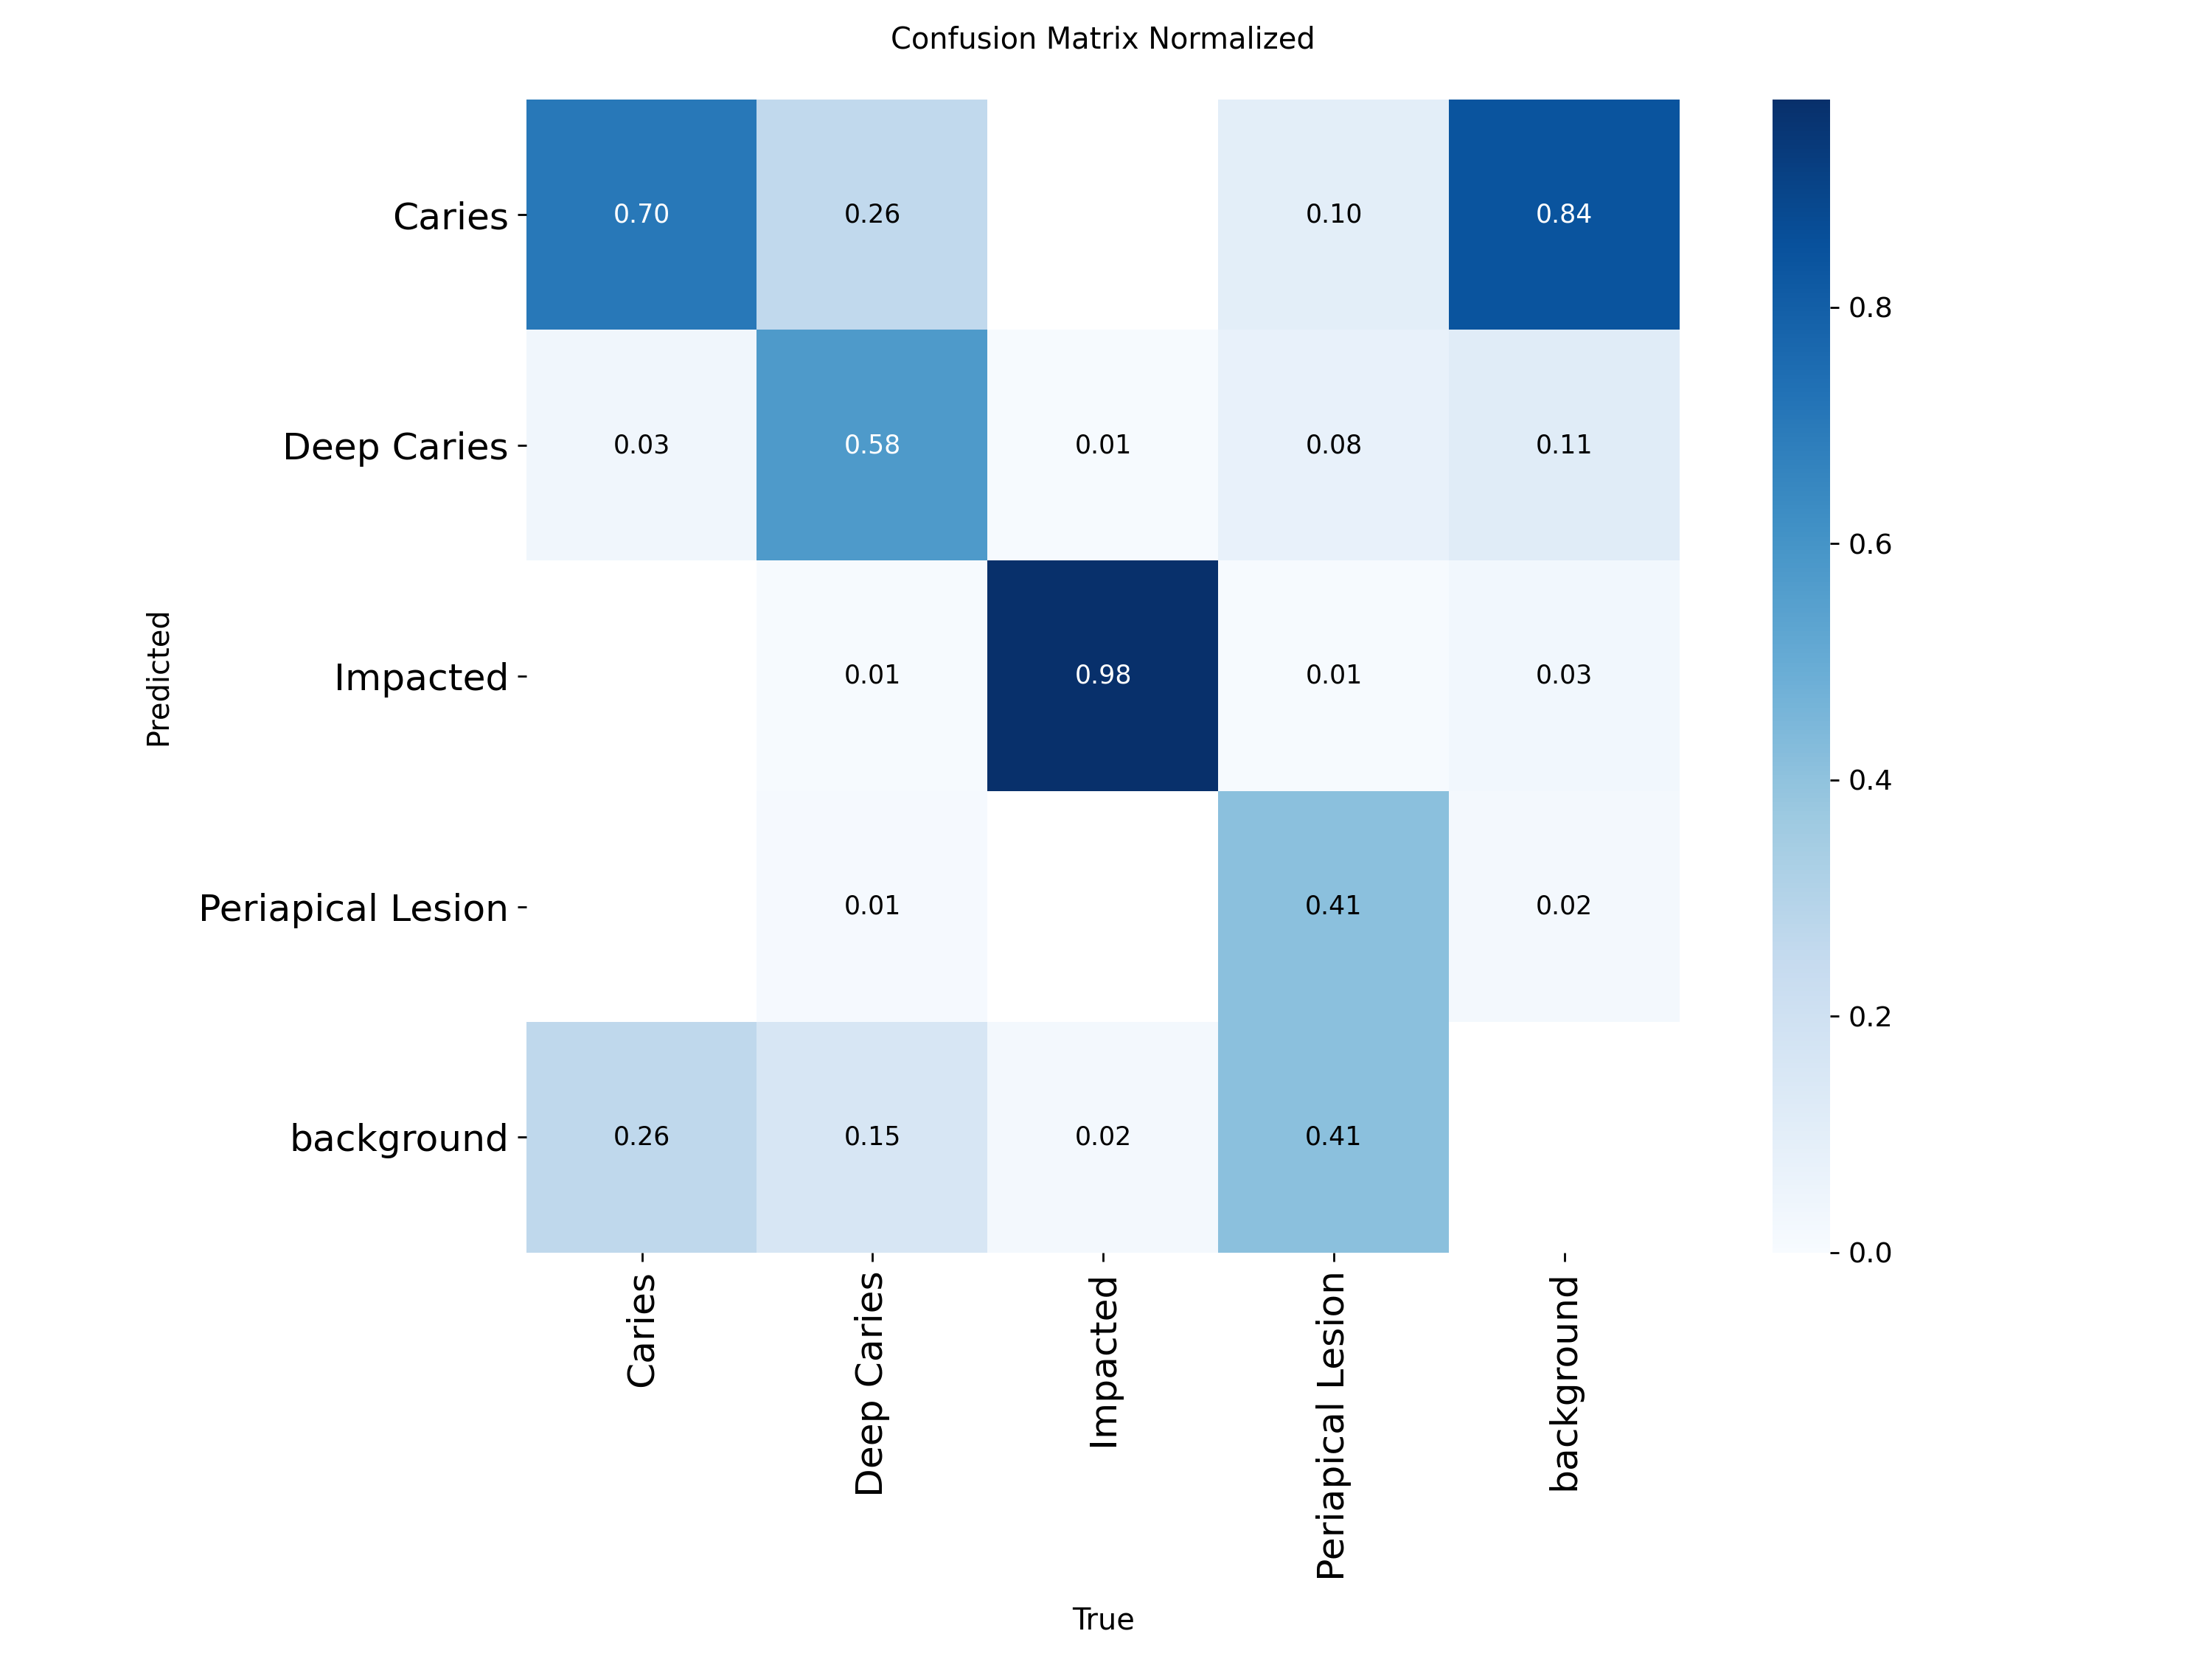

--------------------------------------------------------------------------------
 ĐÃ TÌM THẤY: BoxPR_curve.png


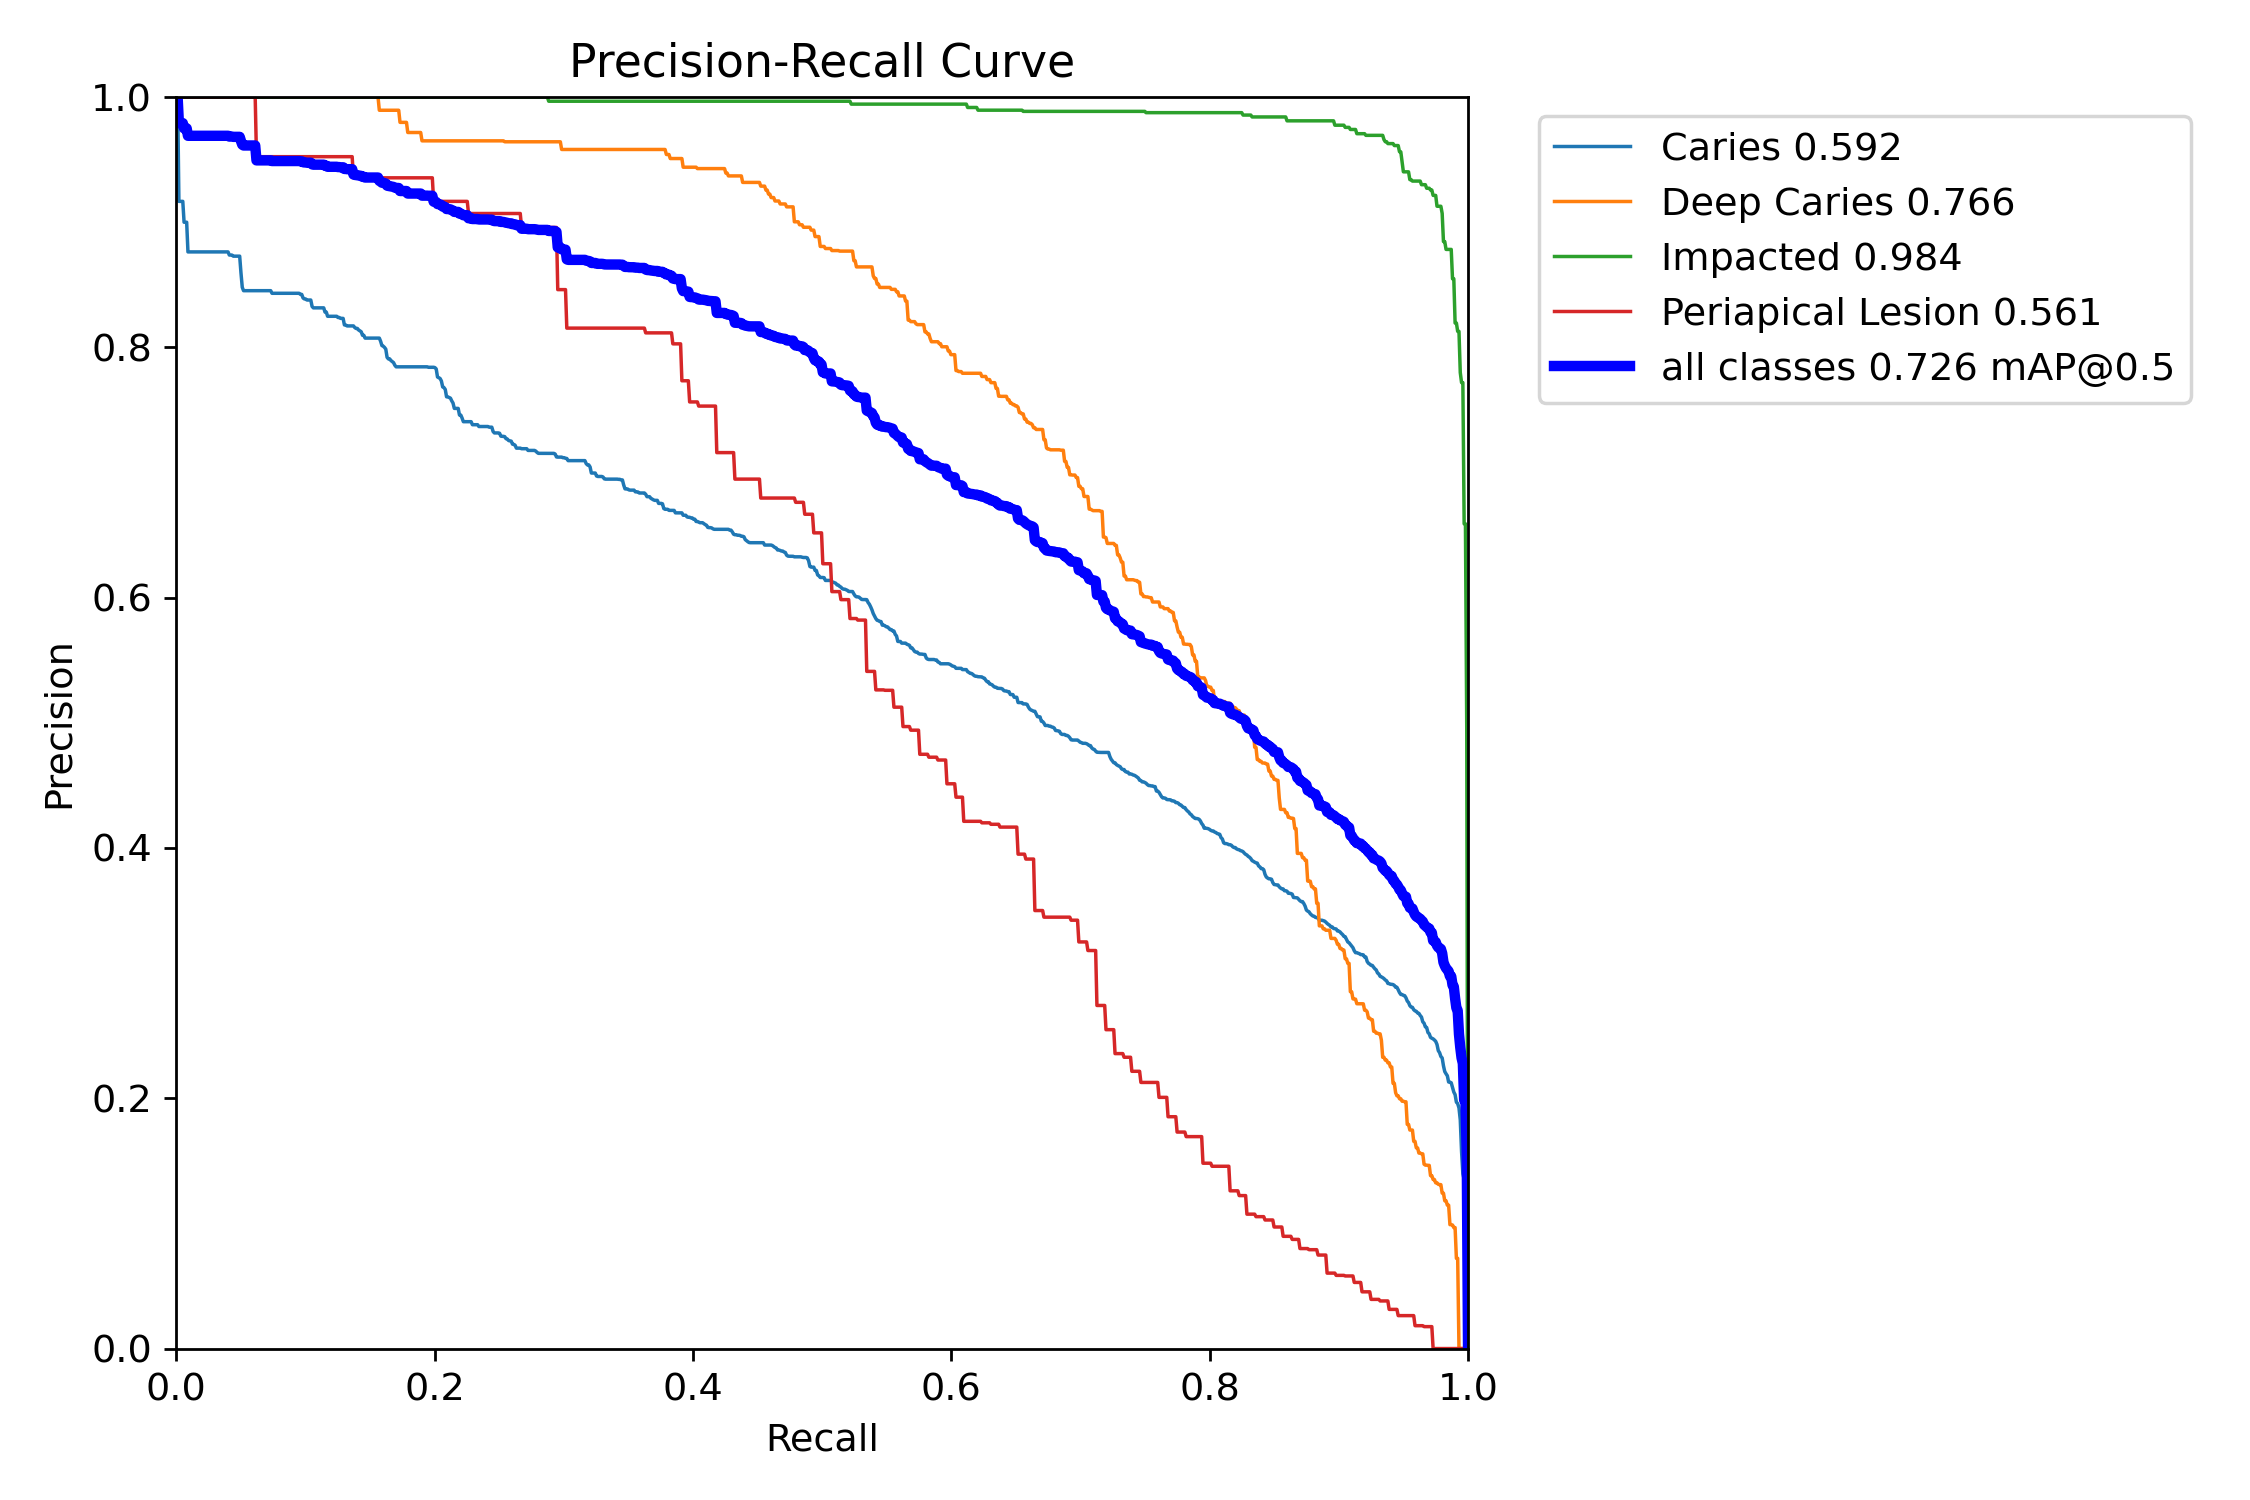

--------------------------------------------------------------------------------
 ĐÃ TÌM THẤY: BoxF1_curve.png


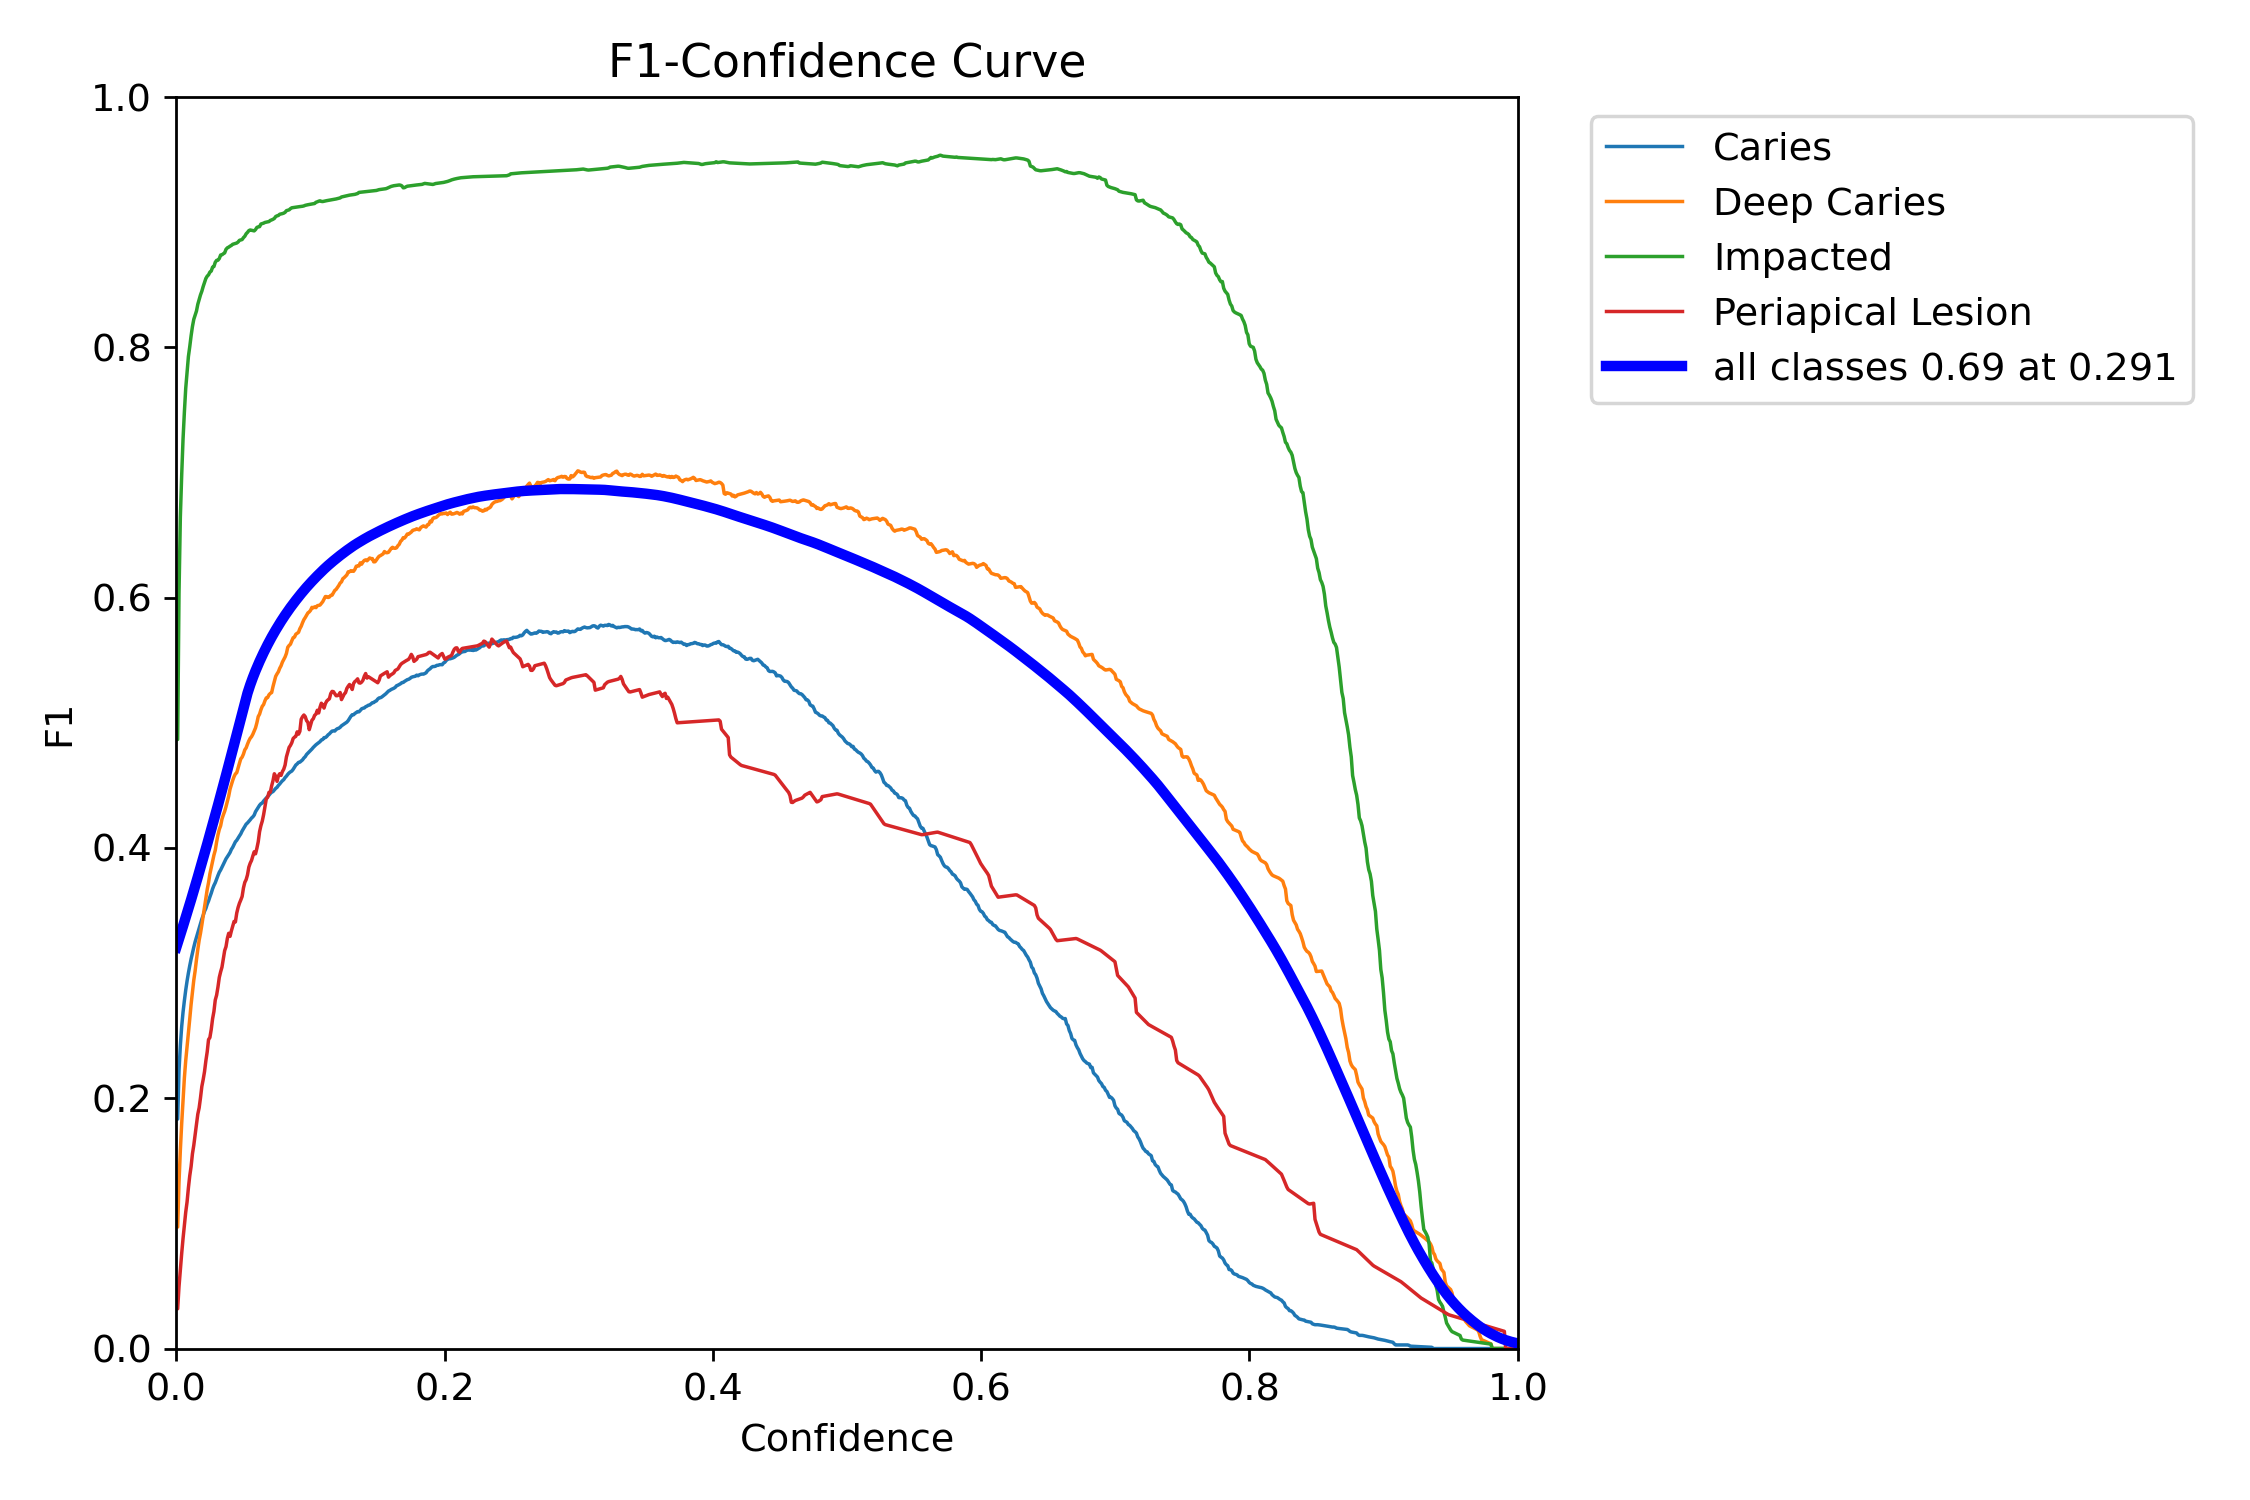

--------------------------------------------------------------------------------
 ĐÃ TÌM THẤY: BoxR_curve.png


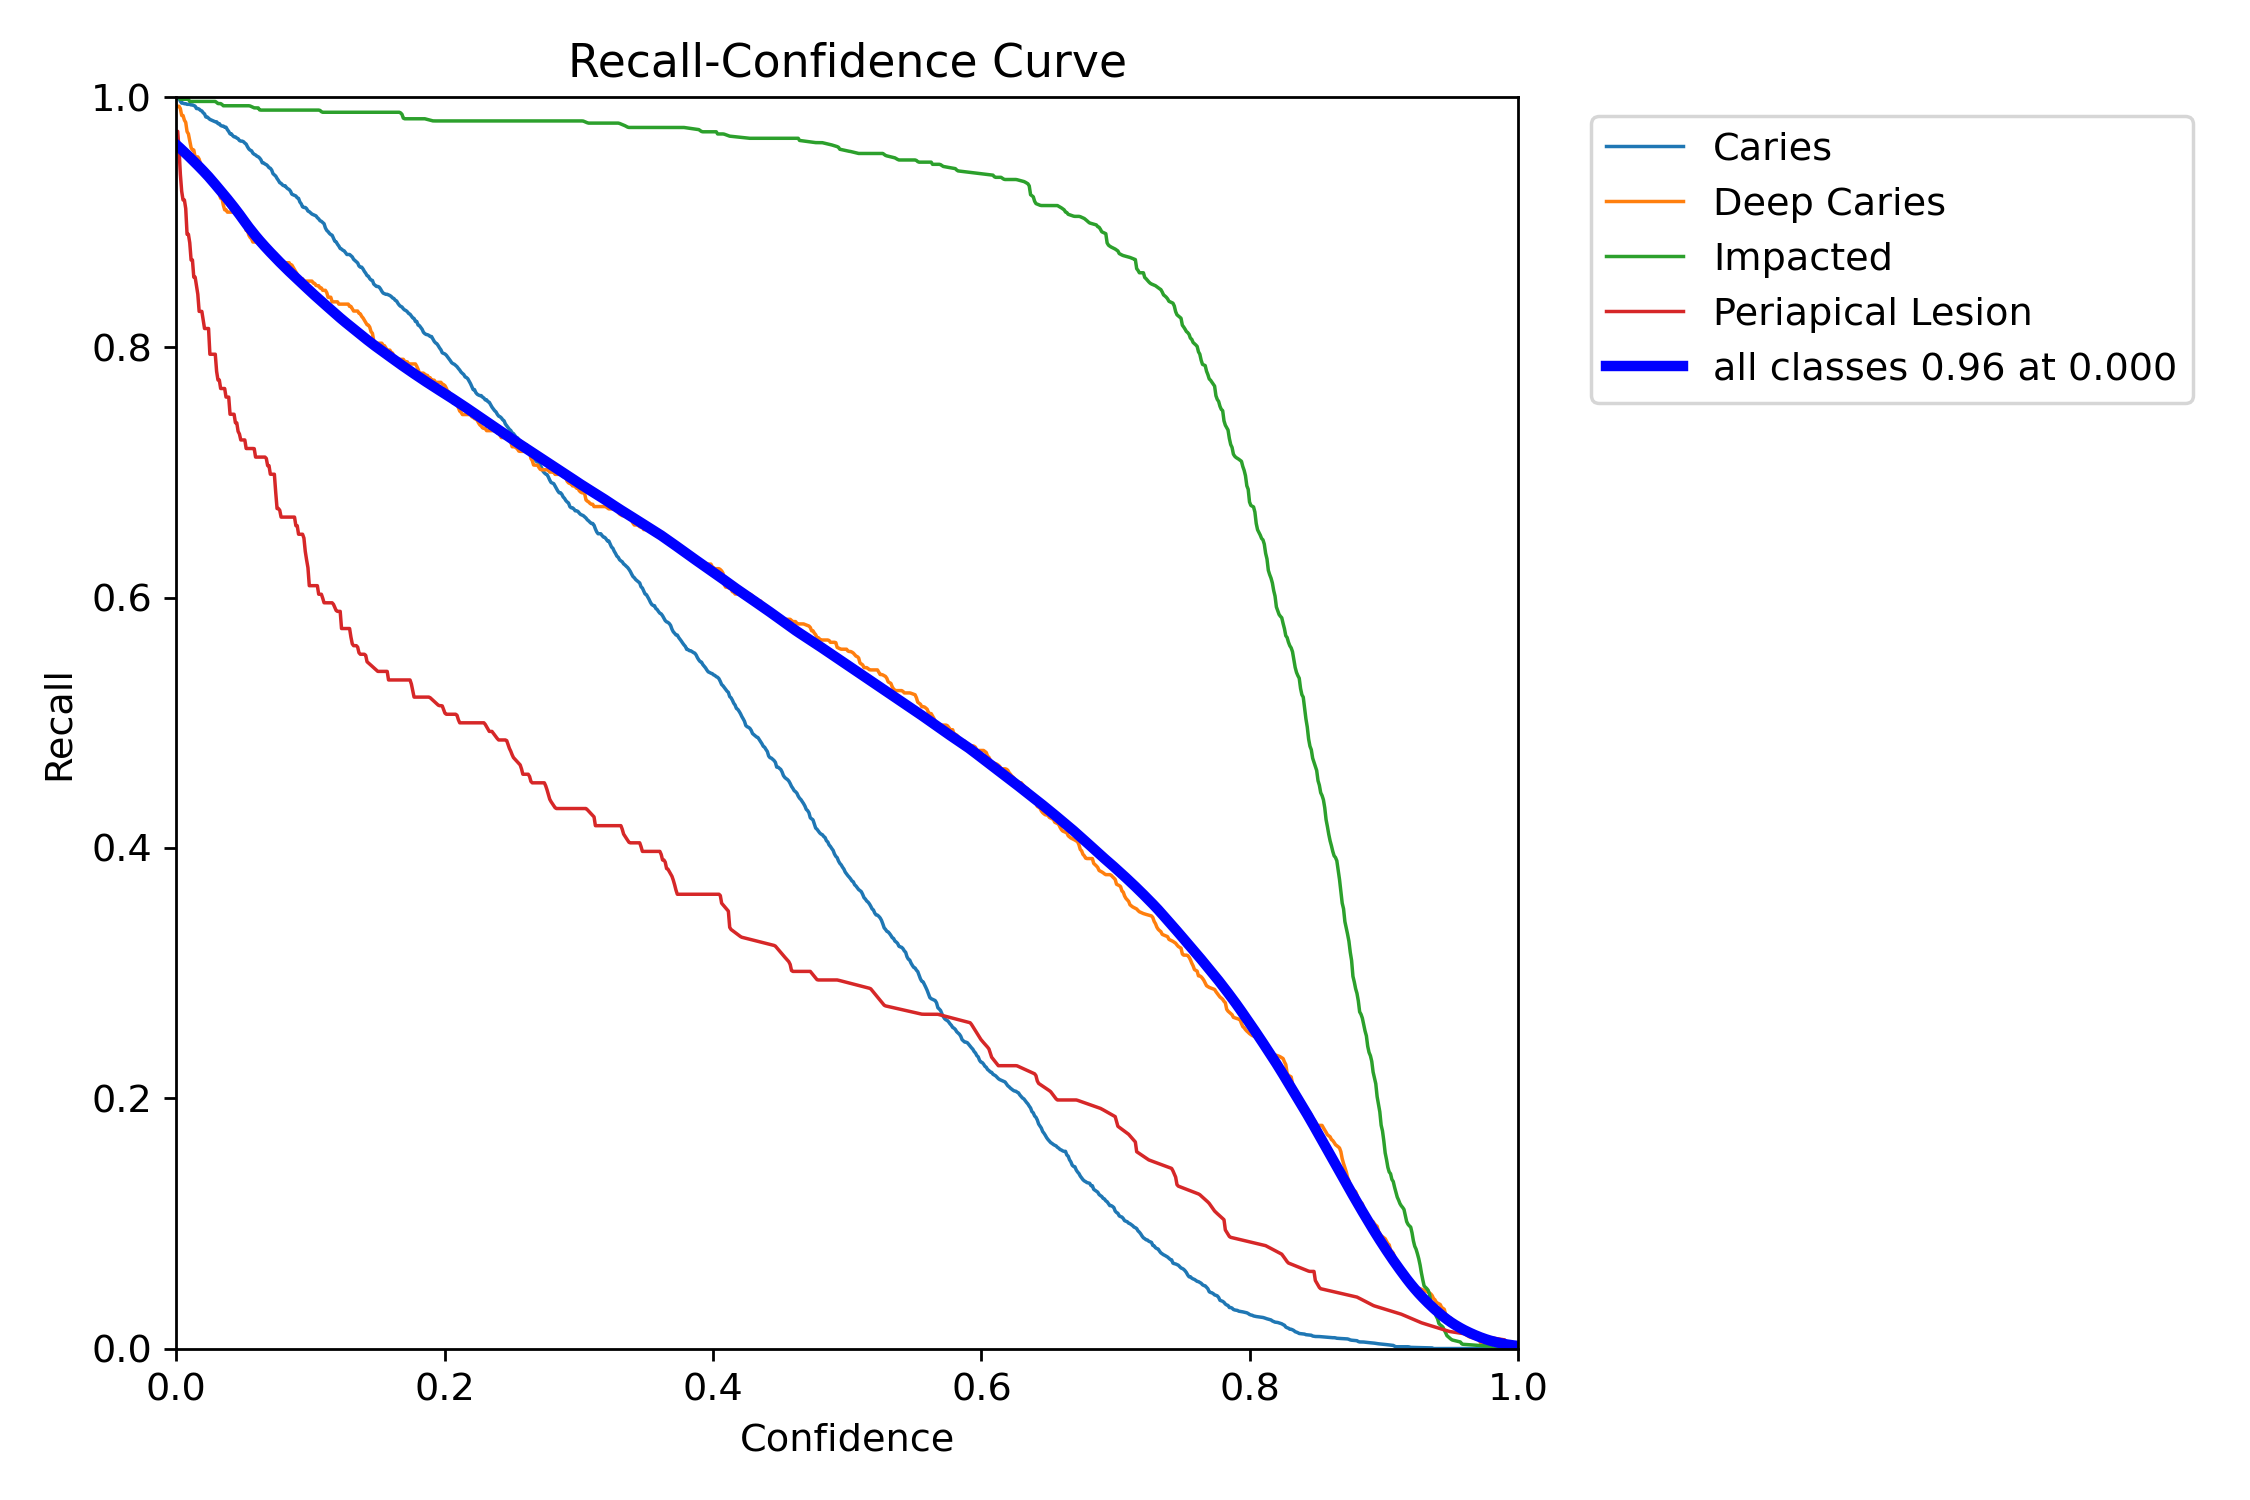

--------------------------------------------------------------------------------
 ĐÃ TÌM THẤY: BoxP_curve.png


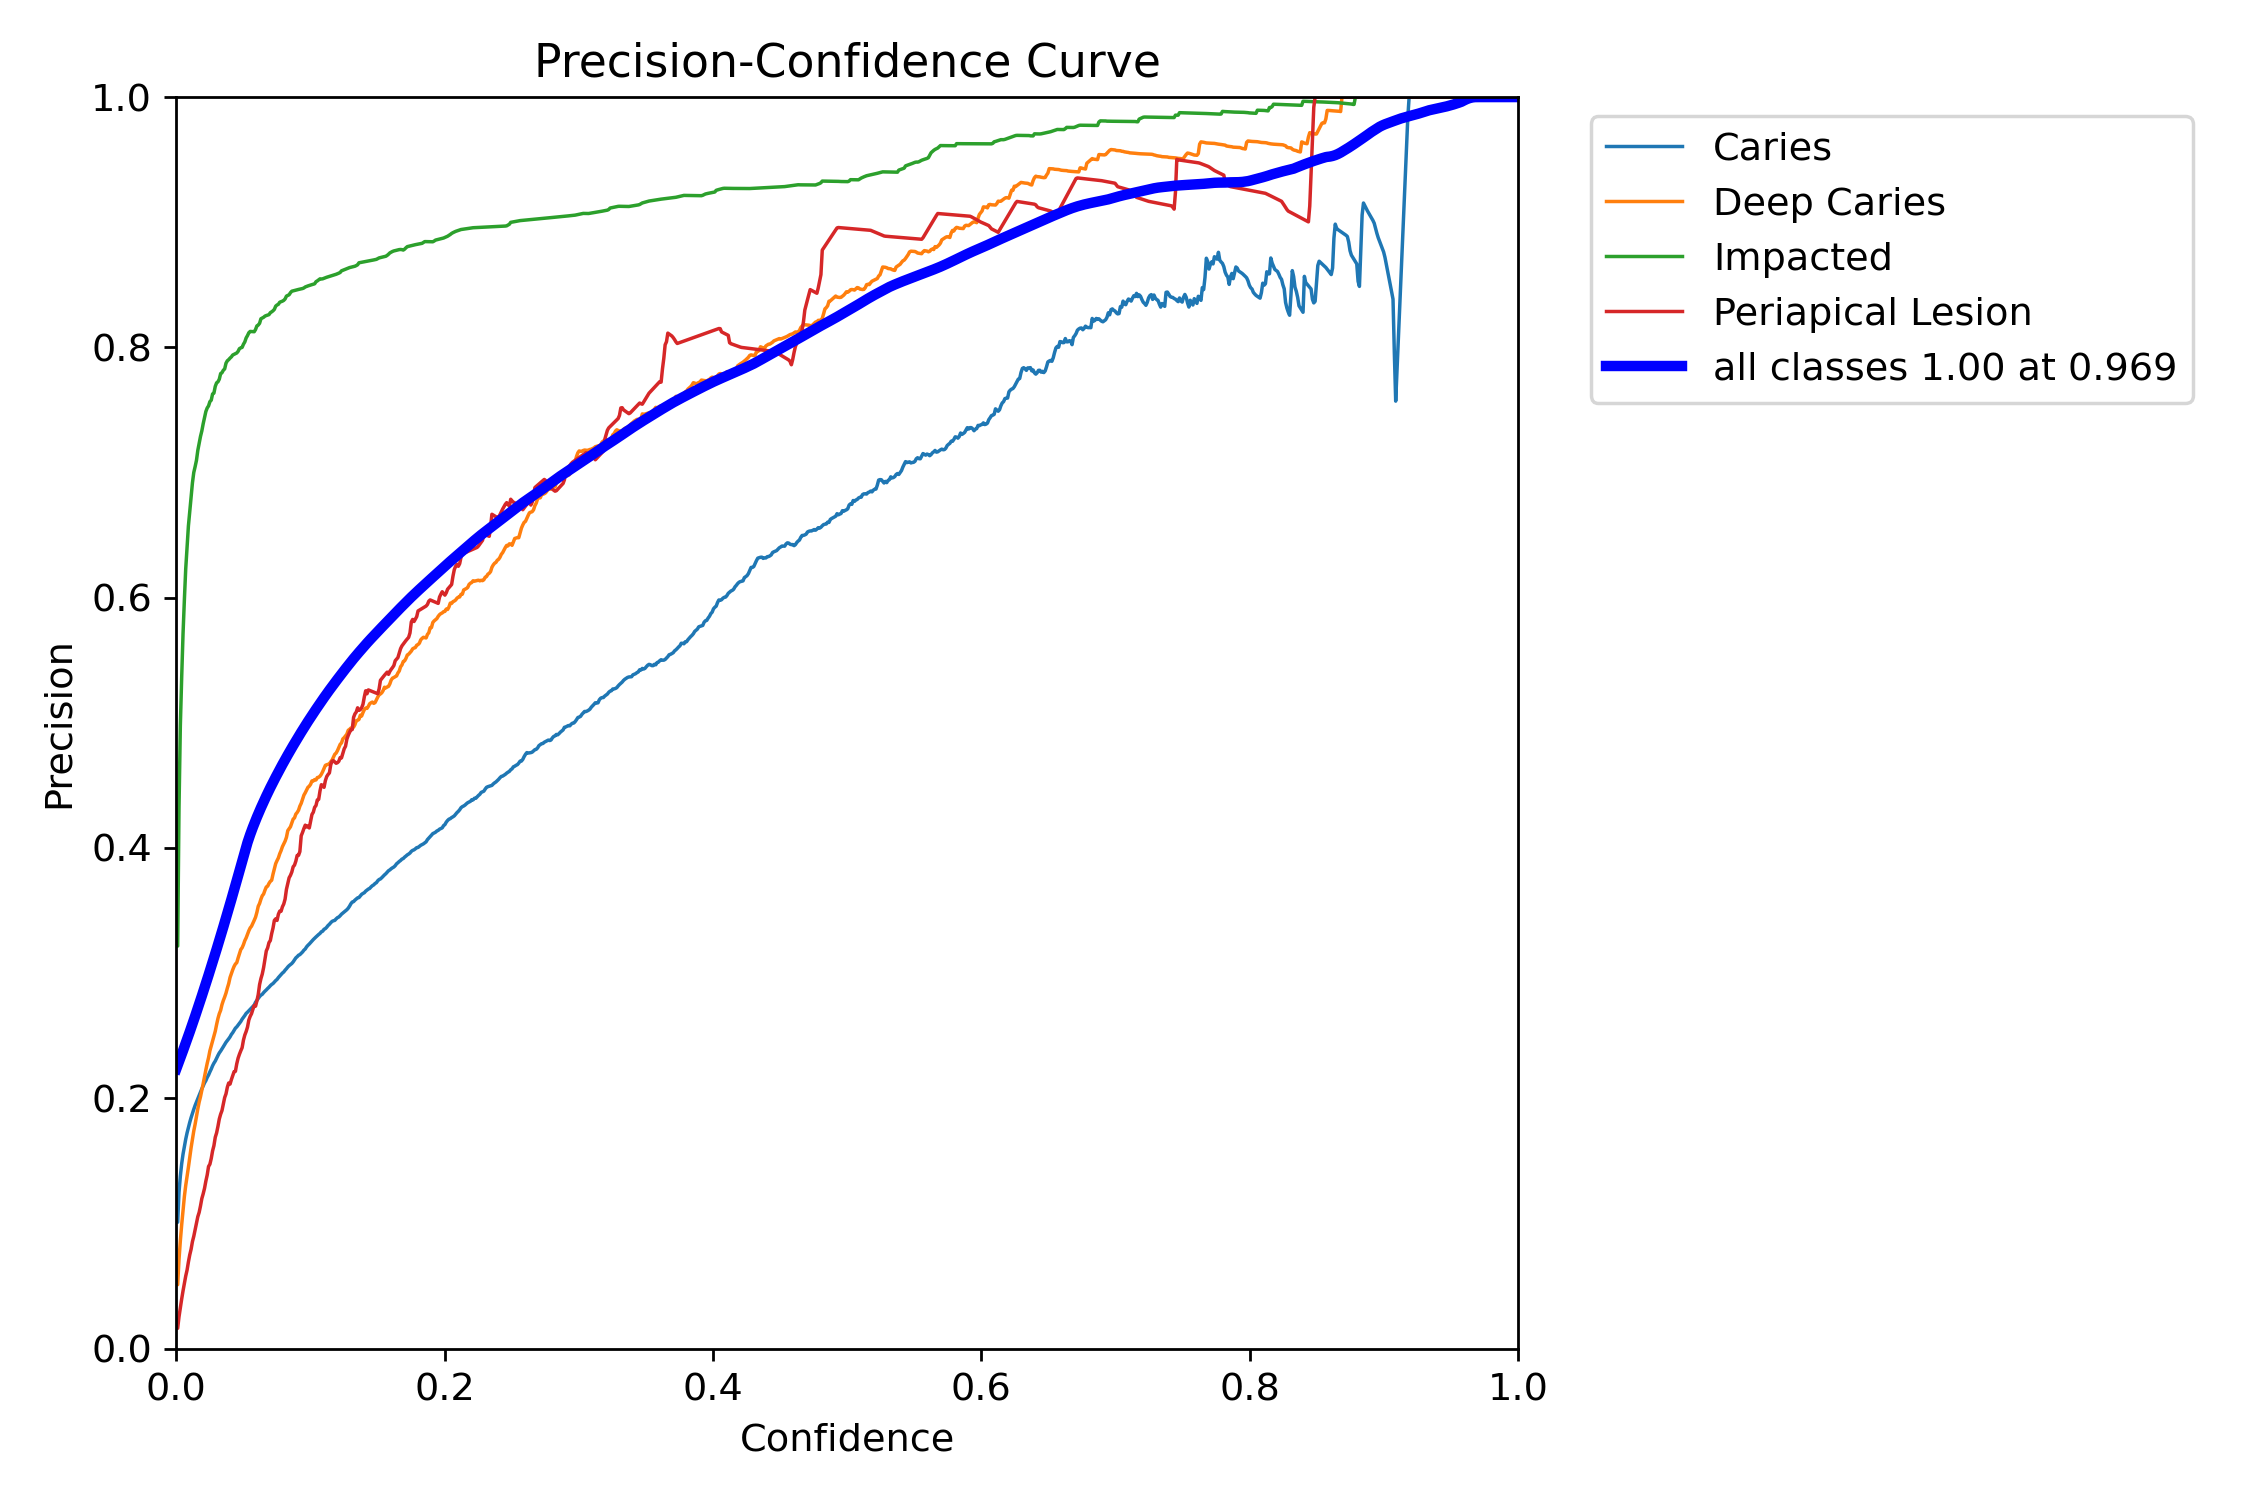

--------------------------------------------------------------------------------
 ĐÃ TÌM THẤY: confusion_matrix.png


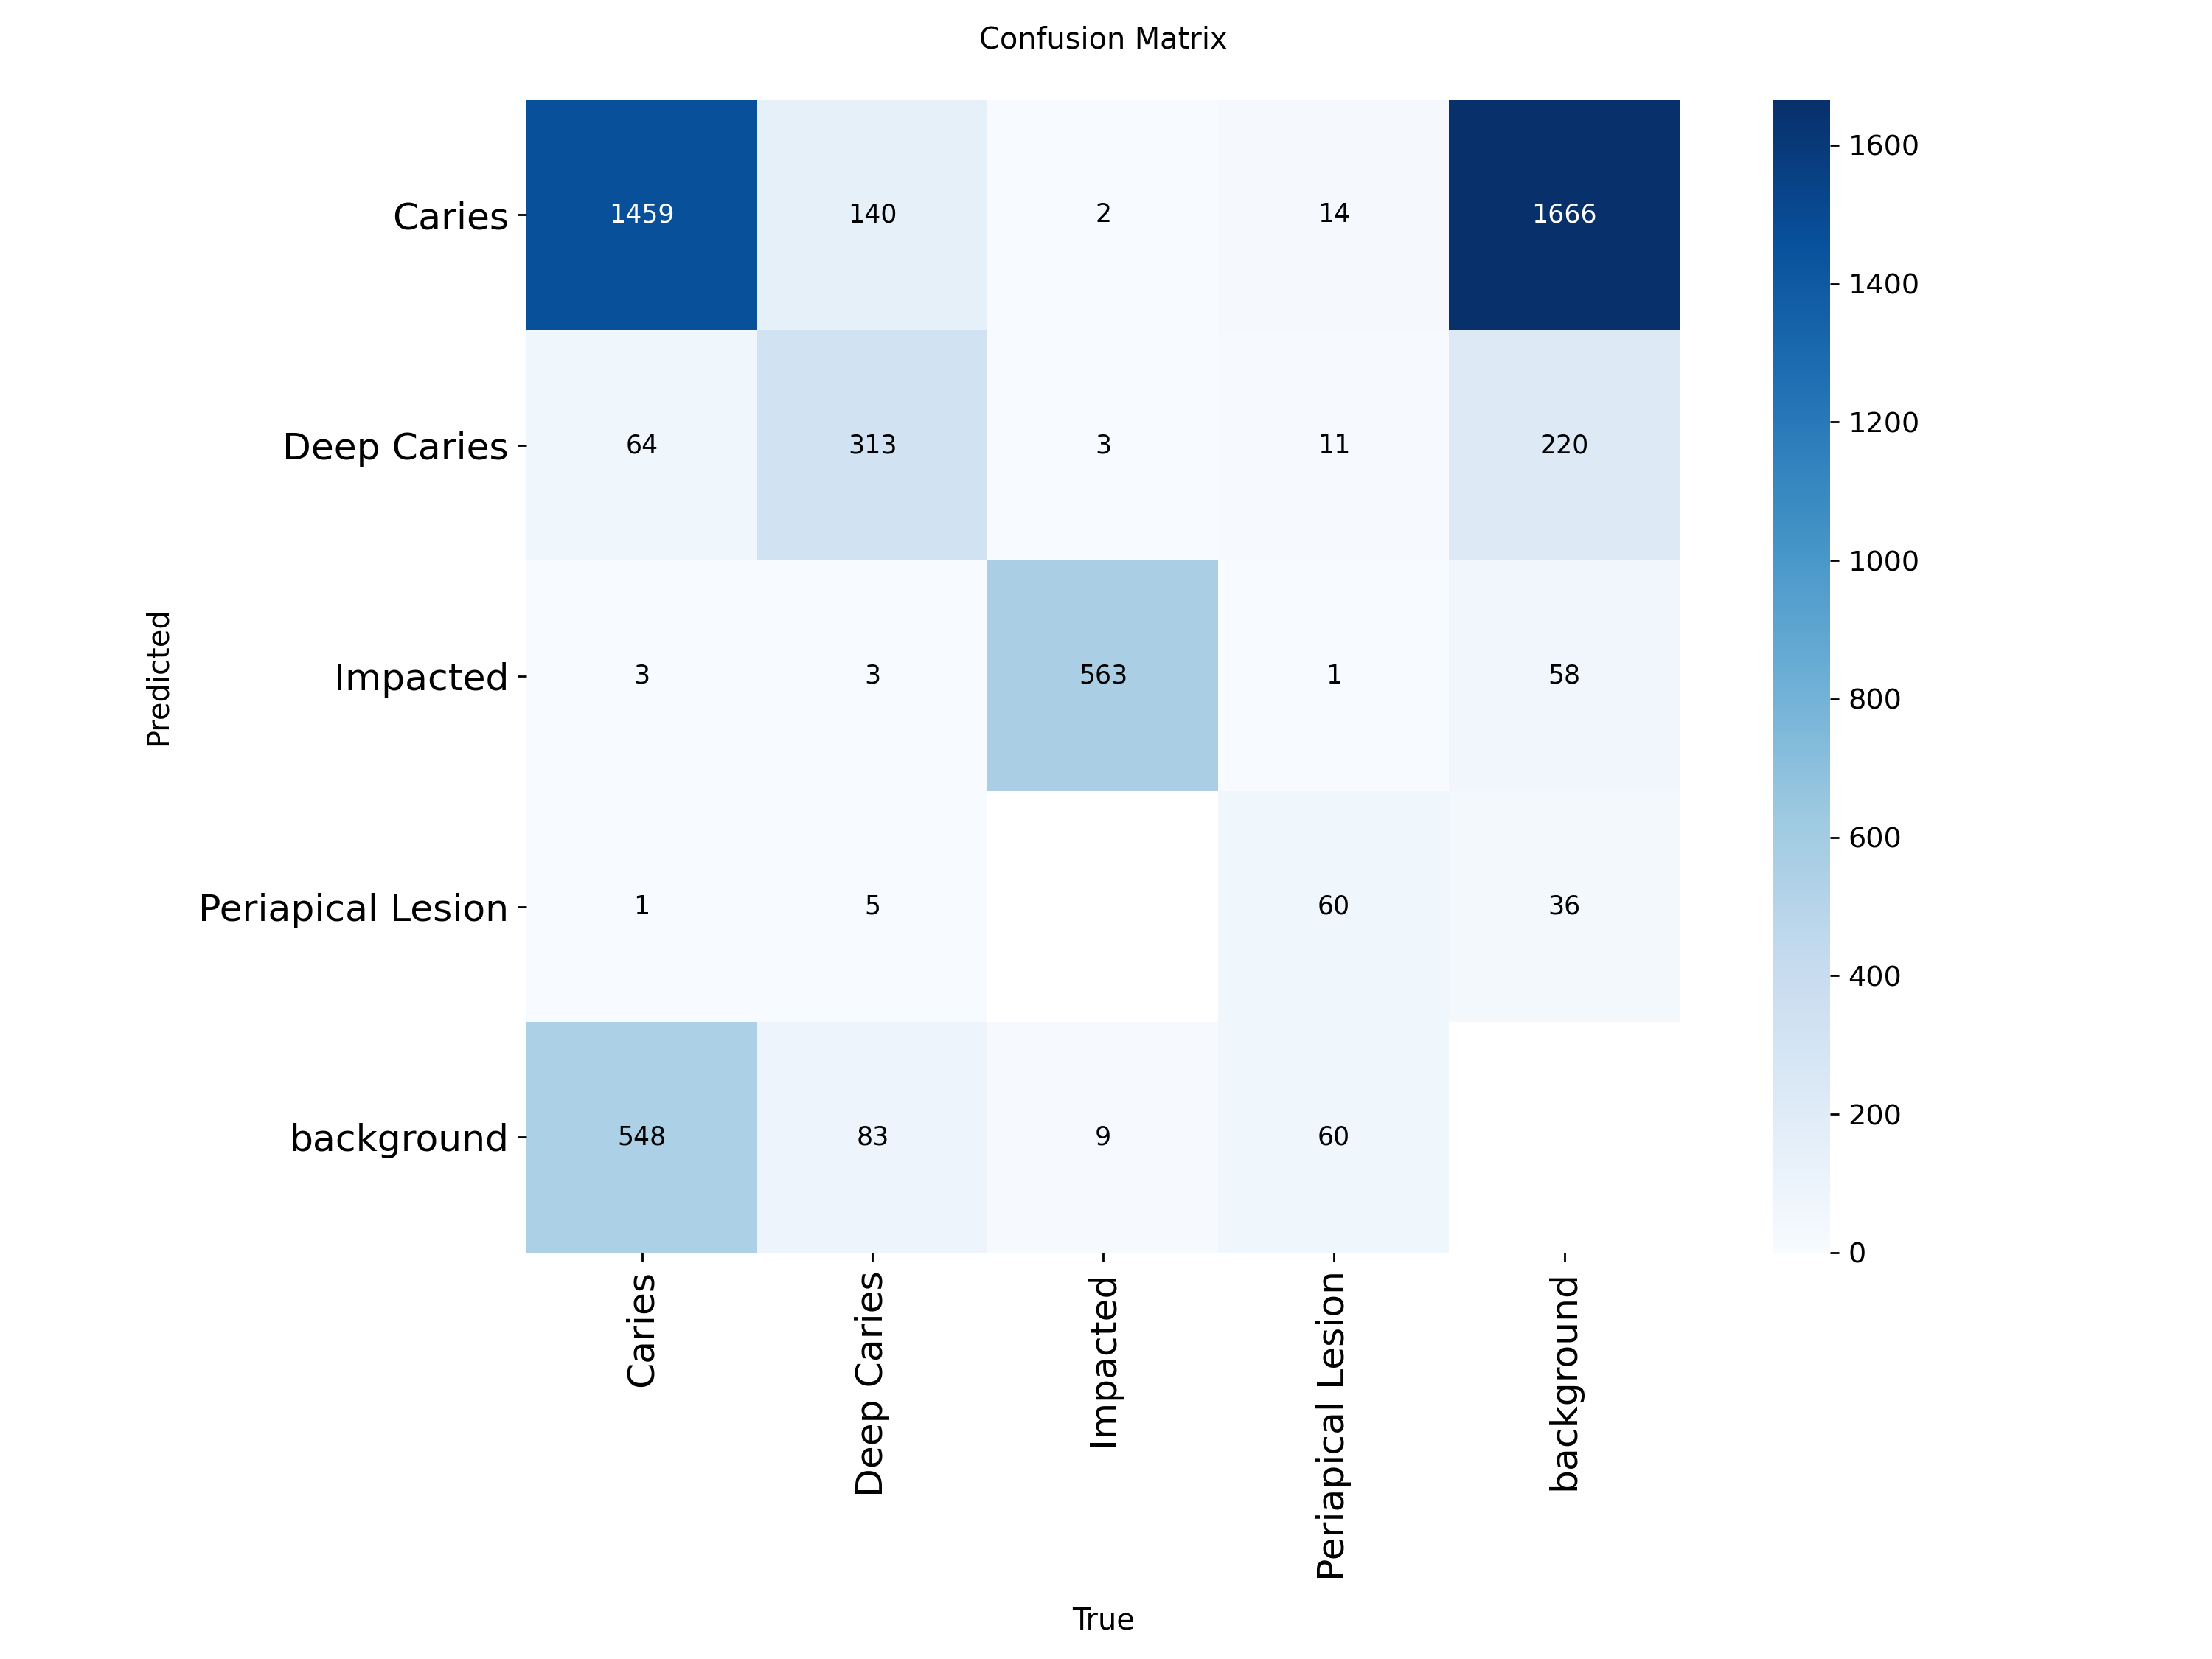

--------------------------------------------------------------------------------


In [5]:
import os
import glob
from IPython.display import Image, display

print("=== QUÉT TOÀN BỘ BIỂU ĐỒ TRONG THƯ MỤC KẾT QUẢ ===")

# Tìm thư mục val mới nhất
danh_sach_thu_muc = glob.glob('/kaggle/working/runs/detect/val*')

if len(danh_sach_thu_muc) > 0:
    thu_muc_moi_nhat = max(danh_sach_thu_muc, key=os.path.getmtime)
    print(f"-> Đang lục lọi trong thư mục: {thu_muc_moi_nhat}\n")

    # Lấy TẤT CẢ các file ảnh đuôi .png có trong thư mục
    tat_ca_anh = glob.glob(os.path.join(thu_muc_moi_nhat, '*.png'))

    if len(tat_ca_anh) > 0:
        for anh in tat_ca_anh:
            ten_file = os.path.basename(anh)
            print(f" ĐÃ TÌM THẤY: {ten_file}")
            display(Image(filename=anh, width=800))
            print("-" * 80)
    else:
        print(f" [CẢNH BÁO] Thư mục {thu_muc_moi_nhat} hoàn toàn trống rỗng không có bức ảnh nào!")
        print("-> Nguyên nhân: Quá trình chấm điểm (model.val) ở ô code trên chưa chạy xong, hoặc bạn chưa tải đúng ảnh.")
        print("-> CÁCH SỬA: Bạn hãy quay lại ô code Bước 3, sửa dòng chấm điểm thành: metrics = model.val(data=yaml_path, plots=True) rồi chạy lại và ĐỢI XONG 100% nhé.")
else:
    print("Không tìm thấy thư mục lưu kết quả nào.")

--- Đang tiến hành phân tích mẫu kiểm thử: train_574_png.rf.bf1de001398ca8652eb5baf300bf9292.jpg ---

0: 352x640 9 Cariess, 51.2ms
Speed: 2.2ms preprocess, 51.2ms inference, 1.5ms postprocess per image at shape (1, 3, 352, 640)


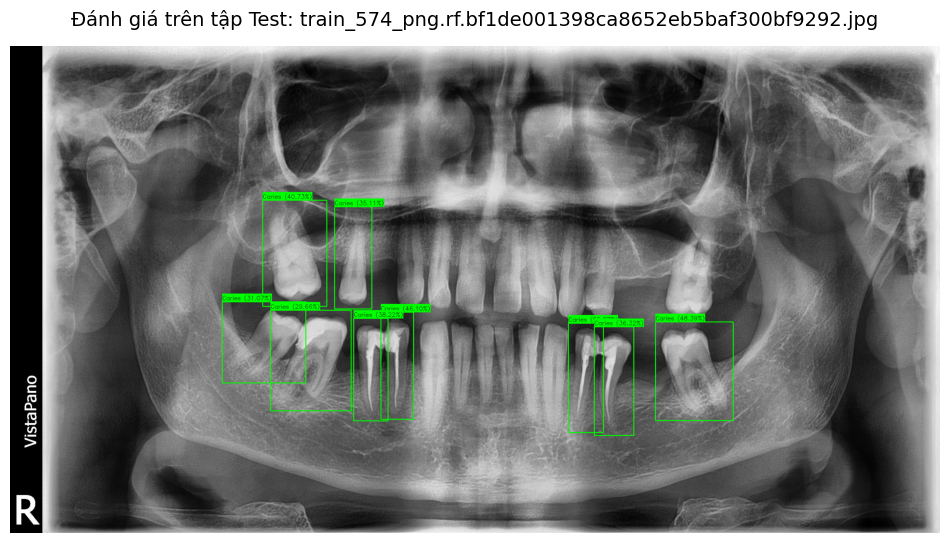

In [6]:
!pip install -q -U ultralytics opencv-python matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import os
import random
import glob

# 1. Cấu hình thư mục chứa ảnh test và đường dẫn mô hình
# Đường dẫn thư mục test mặc định do Roboflow tạo ra trong quá trình tải dữ liệu
test_images_dir = '/kaggle/working/dentex-4/test/images'
model_path = '/kaggle/input/models/ngtrungchinh/yolo11-dentex-model/pytorch/default/1/best (1).pt'

# Kiểm tra tính hợp lệ của hệ thống tệp
if not os.path.exists(test_images_dir):
    raise FileNotFoundError(f"Không tìm thấy thư mục ảnh test tại: {test_images_dir}")
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Không tìm thấy trọng số mô hình tại: {model_path}")

# 2. Trích xuất ngẫu nhiên một mẫu dữ liệu kiểm thử
# Quét toàn bộ các tệp hình ảnh (.jpg, .png, .jpeg) trong tập test
image_list = glob.glob(os.path.join(test_images_dir, '*.*'))

if len(image_list) == 0:
    raise ValueError("Tập dữ liệu test hiện tại đang trống.")

# Lựa chọn ngẫu nhiên một tệp để tiến hành suy luận
image_path = random.choice(image_list)
print(f"--- Đang tiến hành phân tích mẫu kiểm thử: {os.path.basename(image_path)} ---")

# 3. Khởi tạo mô hình YOLO11
model = YOLO(model_path)

# 4. Tiền xử lý ảnh đầu vào
# Mở ảnh bằng PIL và chuyển đổi sang không gian màu RGB tiêu chuẩn
img_pil = Image.open(image_path).convert('RGB')
img_rgb = np.array(img_pil)

# 5. Thực hiện suy luận (Inference) trên toàn bộ các nhãn bệnh lý
results = model.predict(source=img_rgb)
boxes = results[0].boxes 

# 6. Cấu hình màu sắc hiển thị (RGB) cho 4 phân lớp bệnh lý
class_colors = {
    0: (0, 255, 0),    # Lớp 0 (Caries): Xanh lá
    1: (255, 0, 0),    # Lớp 1 (Deep Caries): Đỏ
    2: (0, 150, 255),  # Lớp 2 (Impacted): Xanh dương
    3: (255, 0, 255)   # Lớp 3 (Periapical Lesion): Tím
}

# 7. Trực quan hóa kết quả bằng thư viện OpenCV
for box in boxes:
    # Trích xuất tọa độ không gian của bounding box
    x1, y1, x2, y2 = map(int, box.xyxy[0]) 
    
    # Trích xuất độ tin cậy (Confidence score) và định danh nhãn (Class ID)
    conf = float(box.conf[0])
    cls_id = int(box.cls[0])
    class_name = model.names[cls_id]
    
    # Xác định màu sắc tương ứng với lớp bệnh lý
    color = class_colors.get(cls_id, (255, 255, 0))
    
    # Cấu hình chuỗi văn bản chú thích
    label = f"{class_name} ({conf*100:.2f}%)"
    
    # Vẽ Bounding Box
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 2)
    
    # Thiết kế nền cho văn bản để tối ưu hóa độ tương phản
    (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
    cv2.rectangle(img_rgb, (x1, int(y1 - 25)), (int(x1 + w), y1), color, -1) 
    
    # Chèn văn bản dự đoán (Áp dụng đảo màu văn bản linh hoạt)
    text_color = (0, 0, 0) if cls_id == 0 else (255, 255, 255)
    cv2.putText(img_rgb, label, (x1, int(y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, text_color, 1)

# 8. Kết xuất ảnh kết quả ra màn hình
plt.figure(figsize=(12, 12))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f'Đánh giá trên tập Test: {os.path.basename(image_path)}', fontsize=14, pad=15)
plt.show()

-> Tổng ảnh có nhãn trong tập test: 37/40
-> Đã chọn ngẫu nhiên 5 ảnh để so sánh.



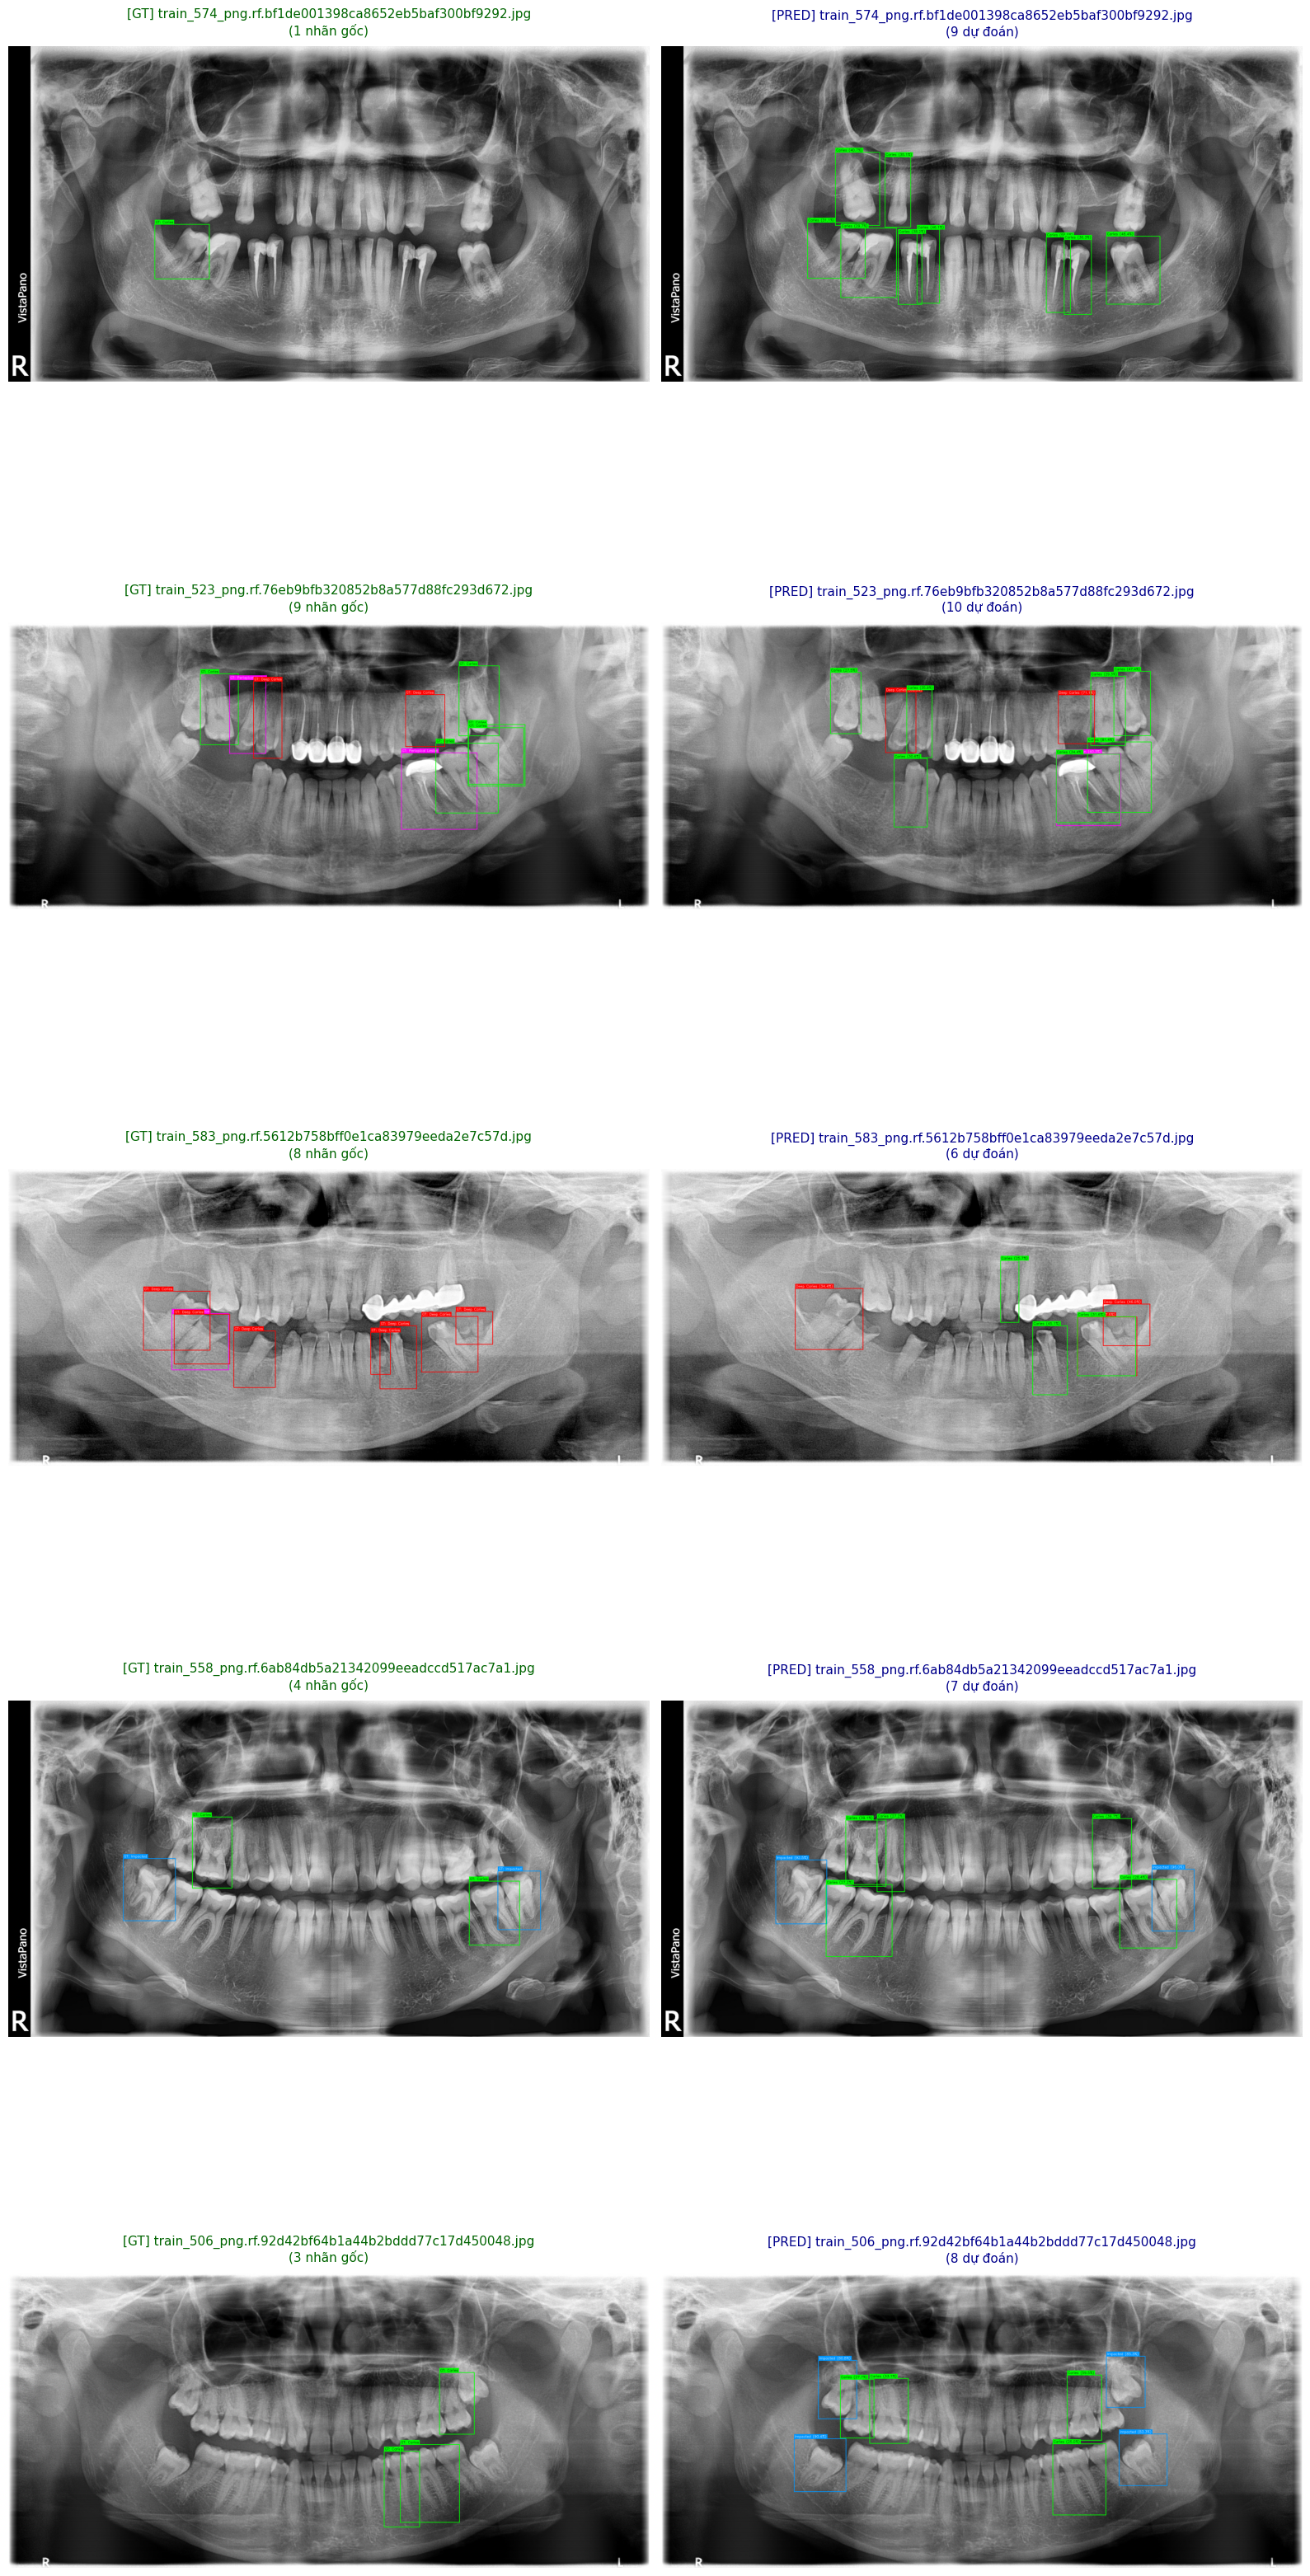

In [20]:
# ==================== CELL 5: SO SÁNH GROUND TRUTH VỚI DỰ ĐOÁN (TẬP TEST) ====================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
import os
import random
import glob

# 1. Cấu hình đường dẫn TẬP TEST
images_dir = '/kaggle/working/dentex-4/test/images'
labels_dir = '/kaggle/working/dentex-4/test/labels'
model_path = '/kaggle/input/models/ngtrungchinh/yolo11-dentex-model/pytorch/default/1/best (1).pt'

if not os.path.exists(images_dir):
    raise FileNotFoundError(f"Không tìm thấy thư mục ảnh tại: {images_dir}")
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Không tìm thấy trọng số mô hình tại: {model_path}")

# 2. Khởi tạo mô hình YOLO11
model = YOLO(model_path)

# Cấu hình màu sắc hiển thị (RGB) cho 4 phân lớp bệnh lý
class_colors = {
    0: (0, 255, 0),    # Lớp 0 (Caries): Xanh lá
    1: (255, 0, 0),    # Lớp 1 (Deep Caries): Đỏ
    2: (0, 150, 255),  # Lớp 2 (Impacted): Xanh dương
    3: (255, 0, 255)   # Lớp 3 (Periapical Lesion): Tím
}

def parse_label_line(parts, img_w, img_h):
    """Đọc nhãn dạng bounding box (5 phần tử) hoặc polygon (>5 phần tử)"""
    cls_id = int(parts[0])
    coords = list(map(float, parts[1:]))
    if len(coords) == 4:
        # Bounding box: x_c, y_c, w, h
        x_c, y_c, w, h = coords
        x1 = int((x_c - w/2) * img_w)
        y1 = int((y_c - h/2) * img_h)
        x2 = int((x_c + w/2) * img_w)
        y2 = int((y_c + h/2) * img_h)
    else:
        # Polygon: x1,y1,x2,y2,...,xn,yn → tính bounding box bao ngoài
        xs = [coords[i] * img_w for i in range(0, len(coords), 2)]
        ys = [coords[i] * img_h for i in range(1, len(coords), 2)]
        x1, y1, x2, y2 = int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))
    x1 = max(0, x1); y1 = max(0, y1)
    x2 = min(img_w, x2); y2 = min(img_h, y2)
    return cls_id, x1, y1, x2, y2

# 3. Lọc ảnh có nhãn hợp lệ (hỗ trợ cả bounding box lẫn polygon)
all_images = glob.glob(os.path.join(images_dir, '*.*'))
labeled_images = []
for img_path in all_images:
    file_id = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(labels_dir, f"{file_id}.txt")
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = [l for l in f.readlines() if len(l.strip().split()) >= 5]
        if len(lines) > 0:
            labeled_images.append(img_path)

print(f"-> Tổng ảnh có nhãn trong tập test: {len(labeled_images)}/{len(all_images)}")
selected_images = random.sample(labeled_images, min(5, len(labeled_images)))
print(f"-> Đã chọn ngẫu nhiên {len(selected_images)} ảnh để so sánh.\n")

# 4. Vẽ lưới so sánh: 5 hàng x 2 cột
fig, axes = plt.subplots(5, 2, figsize=(16, 35))

for idx, img_path in enumerate(selected_images):
    base_name = os.path.basename(img_path)
    file_id   = os.path.splitext(base_name)[0]

    img_pil  = Image.open(img_path).convert('RGB')
    img_w, img_h = img_pil.size
    img_gt   = np.array(img_pil)
    img_pred = np.array(img_pil)

    # -------- A. VẼ GROUND TRUTH (bên trái) --------
    label_path = os.path.join(labels_dir, f"{file_id}.txt")
    gt_count = 0
    with open(label_path, 'r') as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            gt_count += 1
            cls_id, x1, y1, x2, y2 = parse_label_line(parts, img_w, img_h)
            color      = class_colors.get(cls_id, (255, 255, 0))
            class_name = model.names[cls_id]
            label_text = f"GT: {class_name}"
            cv2.rectangle(img_gt, (x1, y1), (x2, y2), color, 2)
            (tw, _), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img_gt, (x1, y1 - 20), (x1 + tw + 6, y1), color, -1)
            text_color = (0, 0, 0) if cls_id == 0 else (255, 255, 255)
            cv2.putText(img_gt, label_text, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, text_color, 1)

    # -------- B. VẼ DỰ ĐOÁN (bên phải) --------
    results    = model.predict(source=img_pred, verbose=False)
    boxes      = results[0].boxes
    pred_count = len(boxes)
    for box in boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf       = float(box.conf[0])
        cls_id     = int(box.cls[0])
        class_name = model.names[cls_id]
        color      = class_colors.get(cls_id, (255, 255, 0))
        label_text = f"{class_name} ({conf*100:.1f}%)"
        cv2.rectangle(img_pred, (x1, y1), (x2, y2), color, 2)
        (tw, _), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img_pred, (x1, y1 - 20), (x1 + tw + 6, y1), color, -1)
        text_color = (0, 0, 0) if cls_id == 0 else (255, 255, 255)
        cv2.putText(img_pred, label_text, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, text_color, 1)

    # -------- C. HIỂN THỊ --------
    axes[idx, 0].imshow(img_gt)
    axes[idx, 0].axis('off')
    axes[idx, 0].set_title(f"[GT] {base_name}\n({gt_count} nhãn gốc)", fontsize=11, color='darkgreen', pad=10)

    axes[idx, 1].imshow(img_pred)
    axes[idx, 1].axis('off')
    axes[idx, 1].set_title(f"[PRED] {base_name}\n({pred_count} dự đoán)", fontsize=11, color='darkblue', pad=10)

plt.tight_layout()
plt.show()
